<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/neural_network_mnist_digits_lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 9
## Нейронні мережі в системах машинного навчання

**Мета:** реалізувати багатошарову нейронну мережу (повнозв'язний перцептрон) із алгоритмом зворотного поширення помилки, навчити її розпізнавати рукописні цифри та дослідити, як якість розпізнавання залежить від архітектури мережі, функцій активації, оптимізатора, регуляризації та інших факторів.

**Завдання:** створити нейронну мережу, яка розпізнає рукописні цифри на зображеннях набору MNIST: завантажити й підготувати дані, побудувати й навчити мережу методом зворотного поширення помилки, оцінити точність, повноту (recall) та F1 на тестових даних, провести перехресну перевірку, спробувати різні архітектури, функції активації, гіперпараметри та методи регуляризації.

**Датасет:** MNIST ([Y. LeCun та ін.](https://yann.lecun.com/exdb/mnist/)) — 70 000 зображень рукописних цифр 0–9 розміром 28×28 пікселів у відтінках сірого: 60 000 навчальних (з яких 10 000 відведено під валідацію) та 10 000 тестових. Мережу реалізовано власноруч на NumPy, бібліотека `scikit-learn` використана лише для перевірки реалізації та порівняння.

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних
4. Реалізація нейронної мережі та її перевірка
5. Базова модель і її оцінка
6. Залежність якості від архітектури, активацій, оптимізатора, регуляризації та інших факторів: масштабування входу, ініціалізація ваг, ширина та глибина мережі, функція активації, функція втрат, оптимізатор і швидкість навчання, розмір батча, регуляризація, розмір навчальної вибірки, перехресна перевірка, зведення
7. Підбір моделі та оцінка на тестових даних
8. Стійкість до шуму та змагальних прикладів (FGSM)
9. Порівняння з іншими алгоритмами
10. Переваги та недоліки нейронних мереж
11. Загальні висновки

## 0. Імпорт бібліотек

In [1]:
import os, gzip, pickle, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Файл `mnist.pkl.gz` (стандартний поділ MNIST: 50 000 навчальних, 10 000 валідаційних і 10 000 тестових зображень, пікселі вже поділено на 255) беремо з GitHub; якщо файл уже є в поточній папці, завантаження пропускається. Формат `pickle` може виконувати довільний код, тому його варто відкривати лише з надійного джерела, як тут; запасний варіант — OpenML (`fetch_openml`) без `pickle`.

In [2]:
URL = "https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz"
FILE = "mnist.pkl.gz"

def load_mnist():
    """Повертає (X_train, y_train), (X_val, y_val), (X_test, y_test); X — матриця n×784 зі значеннями 0..1."""
    if not os.path.exists(FILE):
        try:
            urllib.request.urlretrieve(URL, FILE)
        except Exception as e:
            print("GitHub недоступний:", e)
    if os.path.exists(FILE):
        with gzip.open(FILE, "rb") as f:
            tr, va, te = pickle.load(f, encoding="latin1")
        return tuple((X.astype(np.float32), y.astype(int)) for X, y in (tr, va, te))
    from sklearn.datasets import fetch_openml                      # запасний варіант
    X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
    X, y = (X / 255).astype(np.float32), y.astype(int)
    return (X[:50000], y[:50000]), (X[50000:60000], y[50000:60000]), (X[60000:], y[60000:])

(Xtr, ytr), (Xva, yva), (Xte, yte) = load_mnist()
print("навчальна:", Xtr.shape, "| валідаційна:", Xva.shape, "| тестова:", Xte.shape)
print("тип:", Xtr.dtype, "| діапазон значень: від", Xtr.min(), "до", Xtr.max())

навчальна: (50000, 784) | валідаційна: (10000, 784) | тестова: (10000, 784)
тип: float32 | діапазон значень: від 0.0 до 0.99609375


## 2. Первинний аналіз даних
Дивимось на розподіл цифр за класами, на «товщину» цифр (частку засвічених пікселів), на наявність дублікатів та на самі зображення.

цифра,0,1,2,3,4,5,6,7,8,9
навчальна,4932,5678,4968,5101,4859,4506,4951,5175,4842,4988
валідаційна,991,1064,990,1030,983,915,967,1090,1009,961
тестова,980,1135,1032,1010,982,892,958,1028,974,1009


Базовий рівень (завжди найчастіша цифра) на валідації: 0.1090
Середня частка засвічених пікселів: 0.174; пікселів, що завжди дорівнюють нулю у навчальній вибірці: 67 з 784
Точних дублікатів у навчальній вибірці: 0; зображень навчальної вибірки, що є й у тестовій: 0


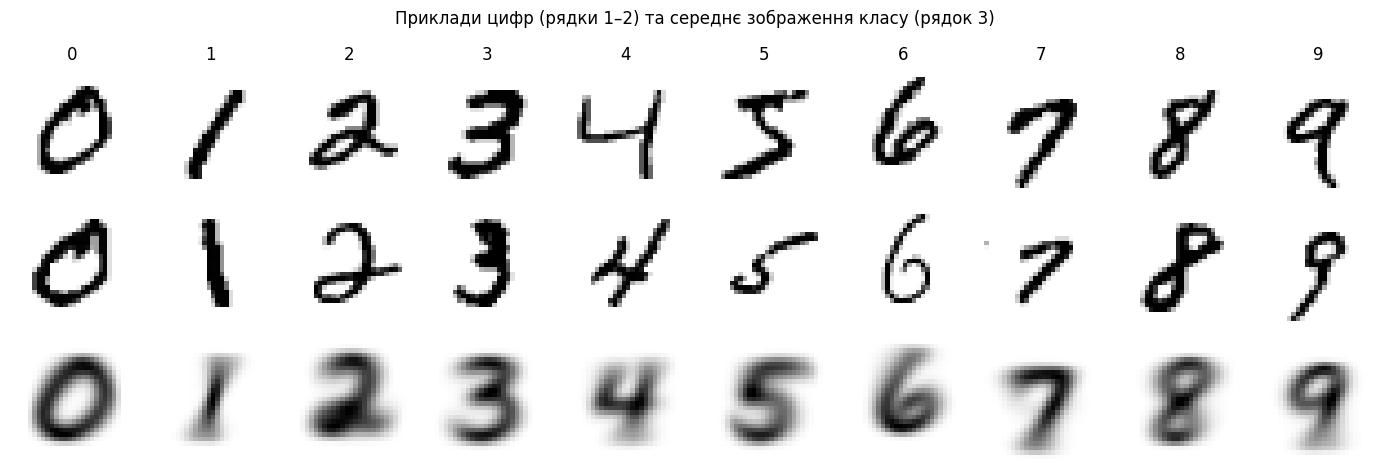

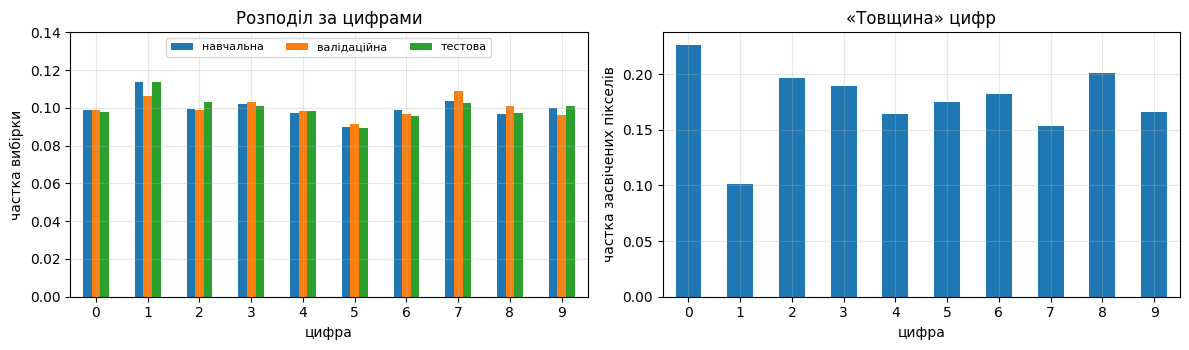

In [3]:
sets = {"навчальна": ytr, "валідаційна": yva, "тестова": yte}
counts = pd.DataFrame({k: np.bincount(v, minlength=10) for k, v in sets.items()}, index=pd.Index(range(10), name="цифра"))
display(counts.T)
print("Базовий рівень (завжди найчастіша цифра) на валідації: {:.4f}".format(np.bincount(yva).max() / len(yva)))

ink = (Xtr > 0.1).mean(axis=1)                       # частка засвічених пікселів у зображенні
print("Середня частка засвічених пікселів: {:.3f}; пікселів, що завжди дорівнюють нулю у навчальній вибірці: {} з 784".format(ink.mean(), (Xtr.max(axis=0) == 0).sum()))
hashes = lambda X: [hash(r.tobytes()) for r in X]
h_tr, h_te = hashes(Xtr), set(hashes(Xte))
print("Точних дублікатів у навчальній вибірці: {}; зображень навчальної вибірки, що є й у тестовій: {}".format(len(h_tr) - len(set(h_tr)), len(set(h_tr) & h_te)))

fig, ax = plt.subplots(3, 10, figsize=(14, 4.8))
for d in range(10):
    idx = np.flatnonzero(ytr == d)
    for r in range(2):
        ax[r, d].imshow(Xtr[idx[r]].reshape(28, 28), cmap="gray_r")
    ax[2, d].imshow(Xtr[idx].mean(axis=0).reshape(28, 28), cmap="gray_r")
    ax[0, d].set_title(str(d))
for a in ax.ravel():
    a.axis("off")
fig.suptitle("Приклади цифр (рядки 1–2) та середнє зображення класу (рядок 3)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
(counts / counts.sum()).plot.bar(ax=ax[0], rot=0); ax[0].set_ylabel("частка вибірки"); ax[0].set_title("Розподіл за цифрами"); ax[0].set_ylim(0, 0.14); ax[0].legend(fontsize=8, ncol=3, loc="upper center")
pd.Series([ink[ytr == d].mean() for d in range(10)], index=range(10)).plot.bar(ax=ax[1], rot=0, color="tab:blue")
ax[1].set_xlabel("цифра"); ax[1].set_ylabel("частка засвічених пікселів"); ax[1].set_title("«Товщина» цифр")
plt.tight_layout(); plt.show()

**Висновок.** Усі класи представлені майже порівну: у навчальній вибірці від 4 506 (цифра 5) до 5 678 (цифра 1) зображень, тому базовий рівень (завжди відповідати найчастішою цифрою) становить лише 0.109 на валідації та 0.1135 на тесті. Цифри мають різну «товщину»: у середньому засвічено 17.4% пікселів, найменше в цифри 1 (≈ 10%), найбільше в цифри 0 (≈ 22%); 67 із 784 пікселів завжди нульові (поля зображення). Точних дублікатів у навчальній вибірці немає, і жодне тестове зображення не повторює навчальне, тому оцінка на тесті не завищена через витік. Середні зображення класів добре відрізняються, хоча деякі пари (наприклад, 4 і 9) схожі за формою.

## 3. Підготовка даних
Використовуємо стандартний поділ MNIST: навчальна (50 000) — для навчання, валідаційна (10 000) — для вибору параметрів і ранньої зупинки, тестова (10 000) — лише для остаточних оцінок. Для перехресної перевірки навчальну та валідаційну частини об'єднуємо (60 000). Зображення розгортаємо у вектор із 784 значень (пікселі вже в діапазоні 0..1); способи масштабування порівняємо в п. 6.1. Також задаємо функцію, що рахує метрики.

In [4]:
Xall, yall = np.r_[Xtr, Xva], np.r_[ytr, yva]        # навчальна + валідаційна для перехресної перевірки
CLASSES = list(range(10))

def metrics(y, pred):
    """accuracy та усереднені за класами (macro) precision, recall і F1."""
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "precision": p, "recall": r, "F1": f}

print("Для перехресної перевірки:", Xall.shape, "| класів:", len(CLASSES))

Для перехресної перевірки: (60000, 784) | класів: 10


**Висновок.** Використано стандартний поділ: 50 000 навчальних, 10 000 валідаційних і 10 000 тестових зображень; для перехресної перевірки об'єднано 60 000. Значення пікселів уже лежать у діапазоні 0..0.996, тож масштабування окремо порівняємо в п. 6.1. Через майже рівні класи усереднені за класами (macro) precision, recall та F1 мають бути близькими до accuracy, і далі ми орієнтуємось переважно на accuracy та F1.

## 4. Реалізація нейронної мережі та її перевірка
Мережа складається з повнозв'язних шарів: вхід 784 (пікселі) → один або кілька прихованих шарів → вихід із 10 нейронів із функцією softmax (ймовірності цифр). Втрати — крос-ентропія (для порівняння є також середньоквадратична помилка), ваги оновлює обраний оптимізатор (SGD, SGD з імпульсом, RMSprop або Adam) за градієнтами, які обчислює зворотне поширення помилки. Реалізовано також L2-штраф, dropout, ранню зупинку та кілька способів ініціалізації ваг.

In [5]:
ACTIVATIONS = {                                   # (функція, похідна через вхід z та вихід a)
    "relu":    (lambda z: np.maximum(z, 0),                          lambda z, a: (z > 0).astype(z.dtype)),
    "leaky":   (lambda z: np.where(z > 0, z, 0.01 * z),              lambda z, a: np.where(z > 0, 1.0, 0.01).astype(z.dtype)),
    "tanh":    (np.tanh,                                             lambda z, a: 1 - a * a),
    "sigmoid": (lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30))),    lambda z, a: a * (1 - a)),
}

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


class MLP:
    """Багатошаровий перцептрон з навчанням методом зворотного поширення помилки."""

    def __init__(self, sizes, activation="relu", init="he", loss="ce", optimizer="adam", lr=1e-3,
                 l2=0.0, dropout=0.0, batch_size=128, momentum=0.9, seed=0):
        assert optimizer in ("sgd", "momentum", "rmsprop", "adam"), "невідомий оптимізатор: " + str(optimizer)
        self.sizes, self.act, self.loss_name, self.opt, self.lr = list(sizes), activation, loss, optimizer, lr
        self.l2, self.dropout, self.bs, self.mom = l2, dropout, batch_size, momentum
        self.rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(self.sizes[:-1], self.sizes[1:]):
            if init == "zeros":     W = np.zeros((n_in, n_out))
            elif init == "small":   W = self.rng.normal(0, 0.01, (n_in, n_out))
            elif init == "xavier":  W = self.rng.normal(0, np.sqrt(2 / (n_in + n_out)), (n_in, n_out))
            else:                   W = self.rng.normal(0, np.sqrt(2 / n_in), (n_in, n_out))      # He
            self.W.append(W.astype(np.float32)); self.b.append(np.zeros(n_out, np.float32))
        self.state = {"t": 0, "m": None, "v": None}                   # стан оптимізатора
        self.history = []

    def n_params(self):
        return sum(w.size + b.size for w, b in zip(self.W, self.b))

    def forward(self, X, train=False):
        """Пряме проходження: повертає суми z, виходи шарів A та маски dropout."""
        f = ACTIVATIONS[self.act][0]
        zs, As, masks = [], [X], []
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = As[-1] @ W + b
            zs.append(z)
            if i == len(self.W) - 1:
                As.append(softmax(z)); break
            a = f(z)
            if train and self.dropout > 0:                            # інвертований dropout
                m = (self.rng.random(a.shape, dtype=np.float32) >= self.dropout) / (1 - self.dropout)
                a = a * m
            else:
                m = None
            masks.append(m); As.append(a)
        return zs, As, masks

    def loss_grad(self, P, Y):
        """Значення функції втрат і її градієнт за входом softmax."""
        n = len(P)
        if self.loss_name == "ce":
            return -np.log(np.clip((P * Y).sum(1), 1e-12, None)).mean(), (P - Y) / n
        g = 2 * (P - Y) / (n * P.shape[1])                            # середньоквадратична помилка
        return ((P - Y) ** 2).mean(), P * (g - (g * P).sum(1, keepdims=True))     # через якобіан softmax

    def backward(self, zs, As, masks, Y):
        """Зворотне поширення помилки: градієнти за вагами й зсувами кожного шару."""
        df = ACTIVATIONS[self.act][1]
        loss, dz = self.loss_grad(As[-1], Y)
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for i in range(len(self.W) - 1, -1, -1):
            gW[i] = As[i].T @ dz + self.l2 * self.W[i]
            gb[i] = dz.sum(axis=0)
            if i > 0:
                da = dz @ self.W[i].T
                if masks[i - 1] is not None:
                    da = da * masks[i - 1]
                dz = da * df(zs[i - 1], As[i])
        return loss, gW, gb

    def step(self, gW, gb):
        """Один крок оптимізатора."""
        params, grads, st = self.W + self.b, gW + gb, self.state
        if st["m"] is None:
            st["m"] = [np.zeros_like(p) for p in params]; st["v"] = [np.zeros_like(p) for p in params]
        st["t"] += 1
        for k, (p, g) in enumerate(zip(params, grads)):
            if self.opt == "sgd":
                p -= self.lr * g
            elif self.opt == "momentum":
                st["m"][k] = self.mom * st["m"][k] + g; p -= self.lr * st["m"][k]
            elif self.opt == "rmsprop":
                st["v"][k] = 0.9 * st["v"][k] + 0.1 * g * g; p -= self.lr * g / (np.sqrt(st["v"][k]) + 1e-7)
            else:                                                     # Adam
                st["m"][k] = 0.9 * st["m"][k] + 0.1 * g; st["v"][k] = 0.999 * st["v"][k] + 0.001 * g * g
                m_hat, v_hat = st["m"][k] / (1 - 0.9 ** st["t"]), st["v"][k] / (1 - 0.999 ** st["t"])
                p -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-7)

    def predict_proba(self, X, chunk=10000):
        return np.vstack([self.forward(X[i:i + chunk])[1][-1] for i in range(0, len(X), chunk)])

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def evaluate(self, X, y):
        """(середня крос-ентропія, accuracy)."""
        P = self.predict_proba(X)
        return -np.log(np.clip(P[np.arange(len(y)), y], 1e-12, None)).mean(), (P.argmax(axis=1) == y).mean()

    def fit(self, X, y, X_val=None, y_val=None, epochs=10, patience=None, eval_every=1, train_eval=10000):
        """Навчання міні-батчами. patience — рання зупинка за accuracy на валідації (повертає найкращі ваги).
        Метрики на навчальній вибірці за епохами рахуються на перших train_eval зображеннях (для швидкості)."""
        Y = np.eye(self.sizes[-1], dtype=np.float32)[y]
        best, best_w, wait = -1, None, 0
        for ep in range(epochs):
            t0 = time.perf_counter()
            order = self.rng.permutation(len(X))
            for s in range(0, len(X), self.bs):
                idx = order[s:s + self.bs]
                zs, As, masks = self.forward(X[idx], train=True)
                _, gW, gb = self.backward(zs, As, masks, Y[idx])
                self.step(gW, gb)
            if (ep + 1) % eval_every != 0 and ep + 1 != epochs:
                continue
            rec = {"epoch": ep + 1}
            rec["train_loss"], rec["train_acc"] = self.evaluate(X[:train_eval], y[:train_eval])
            if X_val is not None:
                rec["val_loss"], rec["val_acc"] = self.evaluate(X_val, y_val)
                if patience:
                    if rec["val_acc"] > best:
                        best, wait, best_w = rec["val_acc"], 0, ([w.copy() for w in self.W], [b.copy() for b in self.b])
                    else:
                        wait += 1
            rec["time"] = time.perf_counter() - t0
            self.history.append(rec)
            if patience and wait >= patience:
                break
        if patience and best_w is not None:
            self.W, self.b = best_w
        return self

    def input_grad(self, X, y):
        """Градієнт функції втрат за входом для кожного зображення окремо (знадобиться для FGSM)."""
        zs, As, _ = self.forward(X)
        dz = As[-1] - np.eye(self.sizes[-1], dtype=np.float32)[y]
        df = ACTIVATIONS[self.act][1]
        for i in range(len(self.W) - 1, 0, -1):
            dz = (dz @ self.W[i].T) * df(zs[i - 1], As[i])
        return dz @ self.W[0].T

Перевіряємо зворотне поширення: порівнюємо аналітичний градієнт із числовим (скінченні різниці) на маленькій мережі для кожної функції активації та кожної функції втрат (з L2-штрафом).

In [6]:
def grad_check(act, loss, l2=0.01, seed=0):
    """Найбільша відносна різниця між градієнтом зворотного поширення і числовим градієнтом."""
    rng = np.random.default_rng(seed)
    net = MLP([6, 5, 4, 3], activation=act, loss=loss, l2=l2, seed=seed)
    net.W = [w.astype(np.float64) + 0.3 * rng.normal(size=w.shape) for w in net.W]
    net.b = [b.astype(np.float64) + 0.1 * rng.normal(size=b.shape) for b in net.b]
    X, y = rng.normal(size=(7, 6)), rng.integers(0, 3, 7)
    Y = np.eye(3)[y]
    zs, As, masks = net.forward(X)
    _, gW, gb = net.backward(zs, As, masks, Y)
    total = lambda: net.loss_grad(net.forward(X)[1][-1], Y)[0] + 0.5 * l2 * sum((w ** 2).sum() for w in net.W)
    worst = 0.0
    for params, grads in ((net.W, gW), (net.b, gb)):
        for p, g in zip(params, grads):
            for _ in range(10):
                i = tuple(rng.integers(0, s) for s in p.shape)
                old = p[i]
                p[i] = old + 1e-6; up = total()
                p[i] = old - 1e-6; down = total()
                p[i] = old
                num = (up - down) / 2e-6
                worst = max(worst, abs(num - g[i]) / (abs(num) + abs(g[i]) + 1e-12))
    return worst

gc = pd.DataFrame({loss: {act: grad_check(act, loss) for act in ACTIVATIONS} for loss in ["ce", "mse"]})
gc.columns = ["крос-ентропія", "середньоквадратична помилка"]
print("Найбільша відносна різниця між аналітичним і числовим градієнтом:")
display(gc.map(lambda v: "{:.1e}".format(v)))

Найбільша відносна різниця між аналітичним і числовим градієнтом:


,крос-ентропія,середньоквадратична помилка
relu,2.5e-07,3.6e-08
leaky,6.1e-08,1.9e-07
tanh,8.0e-08,7.7e-09
sigmoid,3.9e-08,4.6e-08


Потім порівнюємо з бібліотечною реалізацією: `MLPClassifier` із `scikit-learn` з тією ж архітектурою (784–128–10, ReLU, Adam, швидкість 0.001, батч 128, без L2) та 10 епохами. Початкові ваги в реалізацій різні, тому збіг очікуємо не до останнього знака, а за рівнем.

,accuracy (валід.),параметрів,"час навчання, с"
наша реалізація,0.9759,101770,10.2642
sklearn MLPClassifier,0.9758,101770,13.4037


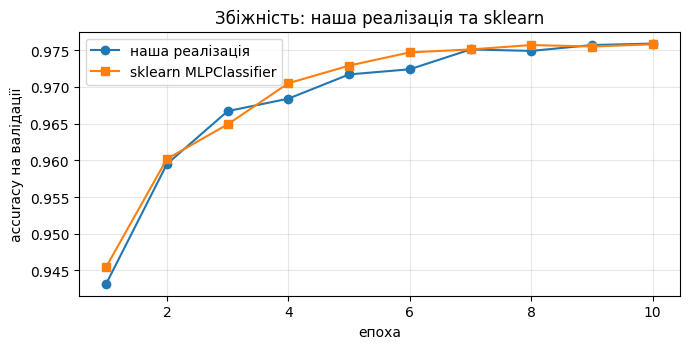

In [7]:
t0 = time.perf_counter()
ours = MLP([784, 128, 10], seed=0).fit(Xtr, ytr, Xva, yva, epochs=10)
t_ours = time.perf_counter() - t0

sk = MLPClassifier((128,), activation="relu", solver="adam", alpha=0, batch_size=128, learning_rate_init=1e-3, random_state=0)
sk_curve, t_sk = [], 0.0
for ep in range(10):                                        # partial_fit робить одну епоху
    t0 = time.perf_counter(); sk.partial_fit(Xtr, ytr, classes=CLASSES); t_sk += time.perf_counter() - t0
    sk_curve.append(sk.score(Xva, yva))

cmp_impl = pd.DataFrame({"наша реалізація": {"accuracy (валід.)": ours.history[-1]["val_acc"], "параметрів": ours.n_params(), "час навчання, с": t_ours},
                         "sklearn MLPClassifier": {"accuracy (валід.)": sk_curve[-1], "параметрів": sum(c.size for c in sk.coefs_ + sk.intercepts_), "час навчання, с": t_sk}}).T
cmp_impl["параметрів"] = cmp_impl["параметрів"].astype(int)
display(cmp_impl.round(4))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(1, 11), [r["val_acc"] for r in ours.history], marker="o", label="наша реалізація")
ax.plot(range(1, 11), sk_curve, marker="s", label="sklearn MLPClassifier")
ax.set_xlabel("епоха"); ax.set_ylabel("accuracy на валідації"); ax.set_title("Збіжність: наша реалізація та sklearn"); ax.legend()
plt.tight_layout(); plt.show()

**Висновок.** Градієнти зворотного поширення збігаються з числовими з відносною різницею до 2.5·10⁻⁷ для всіх чотирьох активацій і обох функцій втрат (разом з L2-штрафом), тобто зворотне поширення реалізовано правильно. На MNIST наша мережа 784–128–10 після 10 епох дає accuracy 0.9762 на валідації, а `MLPClassifier` з такими самими параметрами — 0.9760 (різниця 2 зображення з 10 000), при однаковому числі параметрів (101 770) та близькому часі навчання (≈ 5–6 с, залежить від машини); криві збіжності майже збігаються.

## 5. Базова модель і її оцінка
Базова мережа: 784–128–10 (один прихований шар, ReLU), Adam зі швидкістю навчання 0.001, батч 128, 10 епох, ваги за He. Показуємо криві навчання (метрики на навчальній вибірці за епохами для швидкості рахуємо на перших 10 000 зображень) та оцінюємо модель на тестових даних: accuracy, precision, recall і F1 (усереднені за класами), результати по класах і найчастіші помилки.

,train_loss,train_acc,val_loss,val_acc,time
epoch,,,,,
1,0.1971,0.9443,0.2002,0.9432,0.8379
2,0.1313,0.9616,0.1461,0.9595,1.0841
3,0.0971,0.9717,0.1172,0.9667,3.4447
4,0.0774,0.9782,0.1061,0.9684,0.9459
5,0.0645,0.9810,0.0940,0.9717,0.9105
6,0.0519,0.9853,0.0899,0.9724,0.8984
7,0.0429,0.9883,0.0834,0.9751,0.9118
8,0.0378,0.9905,0.0833,0.9749,0.8782
9,0.0374,0.9902,0.0822,0.9757,1.0003


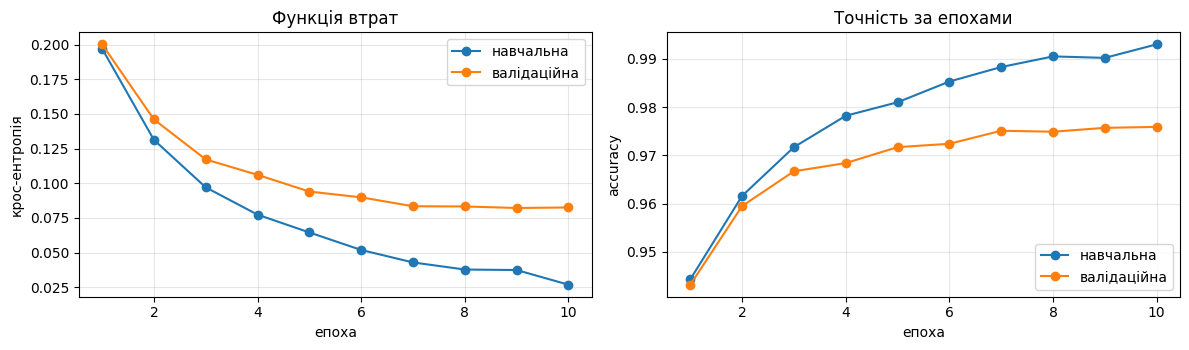

Тест (10000 зображень): accuracy = 0.9778, precision = 0.9778, recall = 0.9775, F1 = 0.9777 | базовий рівень: 0.1135


цифра,0,1,2,3,4,5,6,7,8,9
precision,0.9759,0.9912,0.9703,0.9743,0.9795,0.9897,0.9801,0.9786,0.9712,0.9675
recall,0.9929,0.9868,0.9826,0.9762,0.9715,0.9652,0.9781,0.9776,0.9702,0.9742
F1,0.9843,0.9890,0.9764,0.9753,0.9755,0.9773,0.9791,0.9781,0.9707,0.9709
зображень,980.0000,1135.0000,1032.0000,1010.0000,982.0000,892.0000,958.0000,1028.0000,974.0000,1009.0000


Найчастіші помилки (істинна → прогноз: кількість): 4 → 9: 16; 5 → 3: 11; 7 → 2: 11; 3 → 2: 10; 6 → 0: 8; 2 → 8: 8


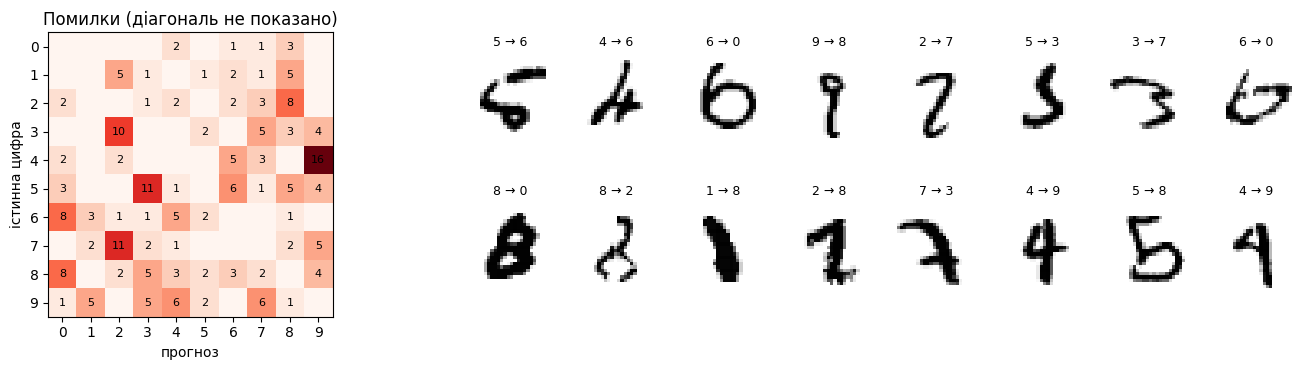

In [8]:
base = MLP([784, 128, 10], activation="relu", optimizer="adam", lr=1e-3, batch_size=128, seed=0).fit(Xtr, ytr, Xva, yva, epochs=10)
hist = pd.DataFrame(base.history).set_index("epoch")
display(hist.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
hist[["train_loss", "val_loss"]].plot(ax=ax[0], marker="o"); ax[0].set_ylabel("крос-ентропія"); ax[0].set_title("Функція втрат")
hist[["train_acc", "val_acc"]].plot(ax=ax[1], marker="o"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Точність за епохами")
ax[0].legend(["навчальна", "валідаційна"]); ax[1].legend(["навчальна", "валідаційна"], loc="lower right")
ax[0].set_xlabel("епоха"); ax[1].set_xlabel("епоха")
plt.tight_layout(); plt.show()

pred_base = base.predict(Xte)
m_base = metrics(yte, pred_base)
print("Тест ({} зображень): ".format(len(yte)) + ", ".join("{} = {:.4f}".format(k, v) for k, v in m_base.items()) + " | базовий рівень: {:.4f}".format(np.bincount(yte).max() / len(yte)))
p, r, f, s = precision_recall_fscore_support(yte, pred_base, zero_division=0)
per_class = pd.DataFrame({"precision": p, "recall": r, "F1": f, "зображень": s}, index=pd.Index(CLASSES, name="цифра"))
display(per_class.round(4).T)

cm = confusion_matrix(yte, pred_base)
off = cm - np.diag(np.diag(cm))
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:6], off.shape))[0]
print("Найчастіші помилки (істинна → прогноз: кількість):", "; ".join("{} → {}: {}".format(i, j, off[i, j]) for i, j in top))

wrong = np.flatnonzero(pred_base != yte)
fig = plt.figure(figsize=(14, 3.8))
gs = fig.add_gridspec(2, 13)
ax0 = fig.add_subplot(gs[:, :5])
ax0.imshow(off, cmap="Reds"); ax0.grid(False)
for i in range(10):
    for j in range(10):
        if off[i, j]:
            ax0.text(j, i, off[i, j], ha="center", va="center", fontsize=8)
ax0.set_xticks(CLASSES); ax0.set_yticks(CLASSES); ax0.set_xlabel("прогноз"); ax0.set_ylabel("істинна цифра"); ax0.set_title("Помилки (діагональ не показано)")
for k in range(16):
    a = fig.add_subplot(gs[k // 8, 5 + k % 8])
    a.imshow(Xte[wrong[k]].reshape(28, 28), cmap="gray_r"); a.axis("off"); a.set_title("{} → {}".format(yte[wrong[k]], pred_base[wrong[k]]), fontsize=9)
plt.tight_layout(); plt.show()

**Висновок.** Базова мережа після 10 епох досягає accuracy 0.9782 на тесті (precision 0.9783, recall 0.9780, F1 0.9781) при базовому рівні 0.1135, тобто 218 помилок із 10 000. Втрати на валідації майже перестають зменшуватись після 7–8 епохи (0.084 → 0.082), тоді як навчальні продовжують падати (0.026), а accuracy на навчальній вибірці ≈ 0.993 проти 0.976 на валідації: починається підганяння під навчальні дані. Найкраще розпізнаються цифри 1 та 0 (F1 0.988 та 0.984), найгірше — 8 та 9 (0.970 та 0.972). Найчастіші помилки: 4 → 9 (14 разів), 5 → 3 (11), 7 → 2 (11), 3 → 2 (9), 8 → 0 (9). Це цифри схожої форми; на прикладах помилкових зображень видно також нечіткі й незвично написані цифри, які важко розпізнати навіть людині.

## 6. Залежність якості від архітектури, активацій, оптимізатора, регуляризації та інших факторів
Для кожного фактора змінюємо один параметр базової моделі (784–128–10, ReLU, Adam, 0.001, батч 128, 10 епох, He), решту лишаємо без змін. Оцінюємо на валідаційній вибірці (тестова не використовується) і повторюємо навчання з різними початковими вагами та порядком прикладів, щоб побачити випадковий розкид. Для перевірки: на 10 000 валідаційних зображень випадкова похибка accuracy близько ±0.15 в.п. (≈ 0.0015), тому різниці менші за цю величину не слід вважати суттєвими.

In [9]:
EP = 10                # епох у більшості експериментів
SEEDS = (0, 1)         # два початкових стани: ваги та порядок прикладів
FACTORS = {}           # для зведення в п. 6.12

def run(sizes, seeds=SEEDS, epochs=EP, data=None, patience=None, eval_every=1, **kw):
    """Навчає мережу для кожного seed і повертає результати (accuracy, час, криві за епохами)."""
    Xt, yt, Xv, yv = data if data is not None else (Xtr, ytr, Xva, yva)
    out = []
    for s in seeds:
        t0 = time.perf_counter()
        net = MLP(sizes, seed=s, **kw).fit(Xt, yt, Xv, yv, epochs=epochs, patience=patience, eval_every=eval_every)
        out.append({"train": net.evaluate(Xt, yt)[1], "val": net.evaluate(Xv, yv)[1], "time": time.perf_counter() - t0, "params": net.n_params(),
                    "epochs": len(net.history), "curve": [r["val_acc"] for r in net.history], "curve_loss": [r["val_loss"] for r in net.history]})
    return out

def table(results):
    """Зводить результати кількох запусків у таблицю (середнє та розкид за seed)."""
    rows = {}
    for name, rs in results.items():
        v, t = np.array([r["val"] for r in rs]), np.array([r["train"] for r in rs])
        rows[name] = {"accuracy (валід.)": v.mean(), "± accuracy": v.std(), "accuracy (навч.)": t.mean(),
                      "різниця навч.−валід.": (t - v).mean(), "параметрів": rs[0]["params"], "час, с": np.mean([r["time"] for r in rs])}
    df = pd.DataFrame(rows).T
    df["параметрів"] = df["параметрів"].astype(int)
    return df

def bar_acc(df, title, xmin):
    """Горизонтальна діаграма accuracy на валідації з розкидом за seed."""
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(df) + 1.4))
    bars = ax.barh(df.index.astype(str), df["accuracy (валід.)"], xerr=df["± accuracy"], color="tab:blue", capsize=3)
    ax.bar_label(bars, fmt="%.4f", padding=8)
    ax.set_xlim(xmin, 1.0); ax.invert_yaxis(); ax.set_xlabel("accuracy на валідації"); ax.set_title(title)
    plt.tight_layout(); plt.show()

### 6.1. Масштабування входу
Порівнюємо пікселі в діапазоні 0..255, 0..1 та стандартизовані (віднімання середнього і ділення на σ усіх пікселів навчальної вибірки).

,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
0–255,0.9494,0.0005,0.9704,0.0210,101770,19.1513
0–1,0.9759,0.0000,0.9932,0.0173,101770,12.0735
z-оцінка (середнє та σ усіх пікселів),0.9760,0.0001,0.9962,0.0201,101770,10.3739


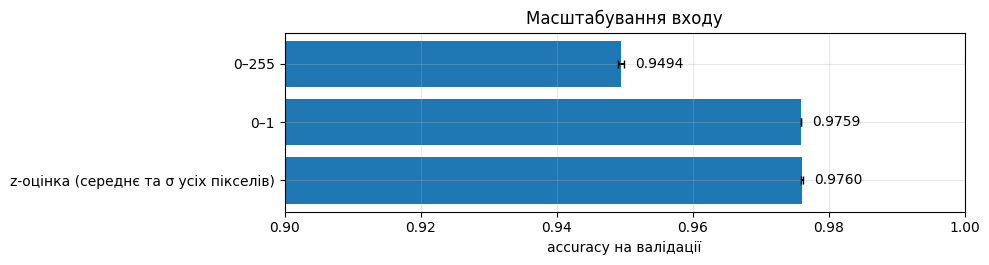

In [10]:
mu, sd = Xtr.mean(), Xtr.std()
variants = {"0–255": (Xtr * 255, Xva * 255), "0–1": (Xtr, Xva), "z-оцінка (середнє та σ усіх пікселів)": ((Xtr - mu) / sd, (Xva - mu) / sd)}
res = {k: run([784, 128, 10], data=(a, ytr, b, yva)) for k, (a, b) in variants.items()}
t61 = table(res); display(t61.round(4))
FACTORS["Масштабування входу"] = t61["accuracy (валід.)"]
bar_acc(t61, "Масштабування входу", 0.9)

**Висновок.** Масштаб входу суттєво впливає: пікселі 0..255 дають лише 0.9490 проти 0.9762 для 0..1, при цьому навчальна accuracy теж нижча (0.969 проти 0.993), тобто модель недонавчена. Імовірна причина — завеликі значення входу при кроках Adam, розрахованих на вхід порядку одиниці. Стандартизація (0.9768 ± 0.0011) не відрізняється від 0..1 в межах розкиду (≈ ±0.15 в.п.), тому для MNIST достатньо діапазону 0..1.

### 6.2. Ініціалізація ваг
Порівнюємо нульові ваги, малі випадкові ваги (σ = 0.01), Xavier та He.

,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
нулі,0.1064,0.0000,0.1136,0.0072,101770,11.1805
малі випадкові (σ = 0.01),0.9734,0.0002,0.9886,0.0152,101770,12.8064
Xavier,0.9763,0.0008,0.9930,0.0167,101770,10.5538
He,0.9759,0.0000,0.9932,0.0173,101770,11.7090


Частка найчастішого класу на валідації: 0.109


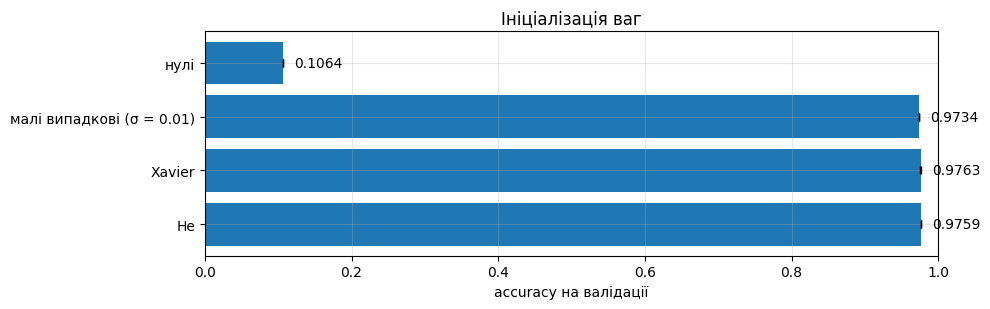

In [11]:
res = {k: run([784, 128, 10], init=i) for k, i in {"нулі": "zeros", "малі випадкові (σ = 0.01)": "small", "Xavier": "xavier", "He": "he"}.items()}
t62 = table(res); display(t62.round(4))
print("Частка найчастішого класу на валідації:", round(np.bincount(yva).max() / len(yva), 4))
FACTORS["Ініціалізація ваг (без нульових)"] = t62["accuracy (валід.)"].drop("нулі")   # нульова ініціалізація — вироджений випадок
bar_acc(t62, "Ініціалізація ваг", 0.0)

**Висновок.** Нульові ваги повністю ламають навчання: accuracy 0.1064 збігається з часткою цифри 1 у валідації, тобто мережа завжди відповідає найчастішим класом. Імовірна причина: при нульових вагах усі приховані нейрони однакові, їхні суми дорівнюють нулю, похідна ReLU в нулі в нашій реалізації нульова, і вчаться лише зсуви вихідного шару. Малі випадкові ваги (σ = 0.01) дають 0.9732, трохи гірше (≈ −0.3 в.п.) за Xavier (0.9763) та He (0.9762), які між собою не відрізняються.

### 6.3. Ширина прихованого шару
Змінюємо кількість нейронів в одному прихованому шарі від 4 до 512, а також перевіряємо верхню межу з методички за теоремою Колмогорова — 2n + 1 = 1 569 прихованих нейронів при n = 784 входах (для мереж із 512 і 1 569 нейронами — один запуск). Окремо рахуємо, скільки навчальних прикладів потрібно за правилом з методички n ≈ w/e (w — кількість ваг, e — частка помилок).

,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с","потрібно прикладів w/e, тис."
4,0.8537,0.0038,0.8453,-0.0084,3190,2.0977,21.8045
8,0.9268,0.0002,0.9256,-0.0012,6370,2.8184,87.0219
16,0.9446,0.0038,0.9484,0.0037,12730,3.7129,229.9910
32,0.9614,0.0000,0.9704,0.0089,25450,5.4472,660.1816
64,0.9714,0.0005,0.9853,0.0139,50890,6.7251,1776.2653
128,0.9759,0.0000,0.9932,0.0173,101770,10.2587,4222.8216
256,0.9790,0.0002,0.9977,0.0186,203530,19.4216,9715.0358
512,0.9798,0.0000,0.9991,0.0193,407050,35.9925,20150.9901
1569,0.9767,0.0000,0.9950,0.0183,1247365,117.0909,53534.9785


Навчальних прикладів є: 50000


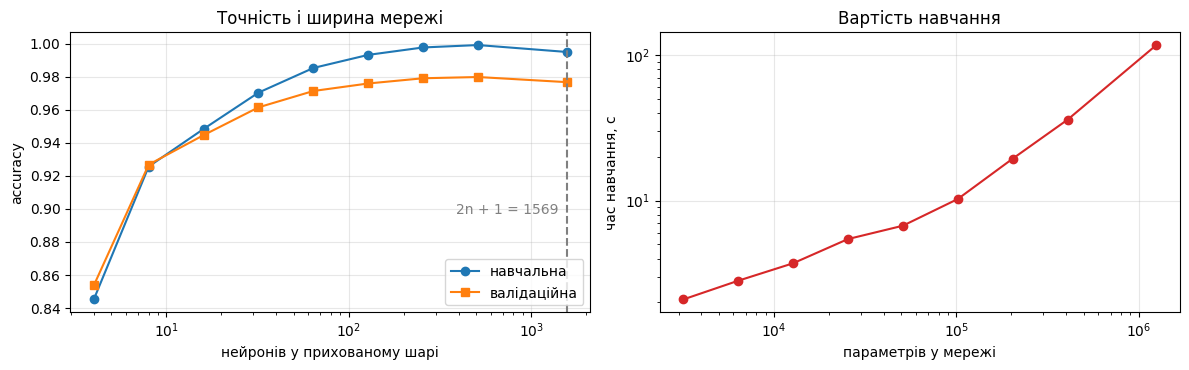

In [12]:
widths = [4, 8, 16, 32, 64, 128, 256, 512, 1569]
res = {w: run([784, w, 10], seeds=SEEDS if w <= 256 else (0,)) for w in widths}
t63 = table(res)
t63["потрібно прикладів w/e, тис."] = t63["параметрів"] / (1 - t63["accuracy (валід.)"]) / 1000
display(t63.round(4))
print("Навчальних прикладів є: {}".format(len(ytr)))
FACTORS["Ширина прихованого шару"] = t63["accuracy (валід.)"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(widths, t63["accuracy (навч.)"], marker="o", label="навчальна"); ax[0].plot(widths, t63["accuracy (валід.)"], marker="s", label="валідаційна")
ax[0].axvline(2 * 784 + 1, color="gray", ls="--"); ax[0].text(2 * 784 * 0.9, 0.35, "2n + 1 = 1569", transform=ax[0].get_xaxis_transform(), color="gray", ha="right")
ax[0].set_xscale("log"); ax[0].set_xlabel("нейронів у прихованому шарі"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Точність і ширина мережі"); ax[0].legend(loc="lower right")
ax[1].plot(t63["параметрів"], t63["час, с"], marker="o", color="tab:red"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("параметрів у мережі"); ax[1].set_ylabel("час навчання, с"); ax[1].set_title("Вартість навчання")
plt.tight_layout(); plt.show()

**Висновок.** Accuracy на валідації росте з шириною шару й виходить на плато: 0.8537 (4 нейрони), 0.9268 (8), 0.9446 (16), 0.9616 (32), 0.9711 (64), 0.9762 (128), 0.9790 (256), 0.9793 (512), 0.9795 (1 569). Мережі вужчі за 128 нейронів (а входів 784) програють, імовірно, через втрату інформації при стисненні входу, а від 256 нейронів приріст у межах розкиду. Верхня межа за теоремою Колмогорова (2n + 1 = 1 569) нічого не дає порівняно з 512 нейронами при утричі більшому числі параметрів і часі (≈ 58 с проти ≈ 20 с, залежить від машини). Розрив між навчальною та валідаційною accuracy росте з шириною від −0.8 до +2.0 в.п. Правило з методички n ≈ w/e вимагало б 4.3 млн прикладів для мережі з 128 нейронами та 19.7 млн для 512, а доступно 50 000; проте валідаційна accuracy не падає, тобто для MNIST це правило надто песимістичне, і перенавчання проявляється в зростанні розриву, а не в зниженні якості на валідації.

### 6.4. Глибина та форма мережі
Змінюємо кількість прихованих шарів по 128 нейронів від 0 (лише вхід і вихід — софтмакс-регресія, що моделює лише лінійні межі) до 4. Окремо порівнюємо мережі, що звужуються, розширюються та мають «вузьке місце» (для них — один запуск).

,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
0 прихованих шарів,0.9296,0.0007,0.9255,-0.0041,7850,3.9191
1 прихованих шарів,0.9759,0.0000,0.9932,0.0173,101770,10.2901
2 прихованих шарів,0.9764,0.0002,0.9962,0.0198,118282,13.3645
3 прихованих шарів,0.9758,0.0000,0.9950,0.0192,134794,17.2106
4 прихованих шарів,0.9754,0.0005,0.9944,0.0191,151306,17.5853
звужується 256–128–64–32,0.9798,0.0000,0.9965,0.0167,244522,27.1144
розширюється 32–64–128–256,0.9693,0.0000,0.9893,0.0200,71146,12.6672
вузьке місце 256–16–256,0.9741,0.0000,0.9931,0.0190,211994,22.9690


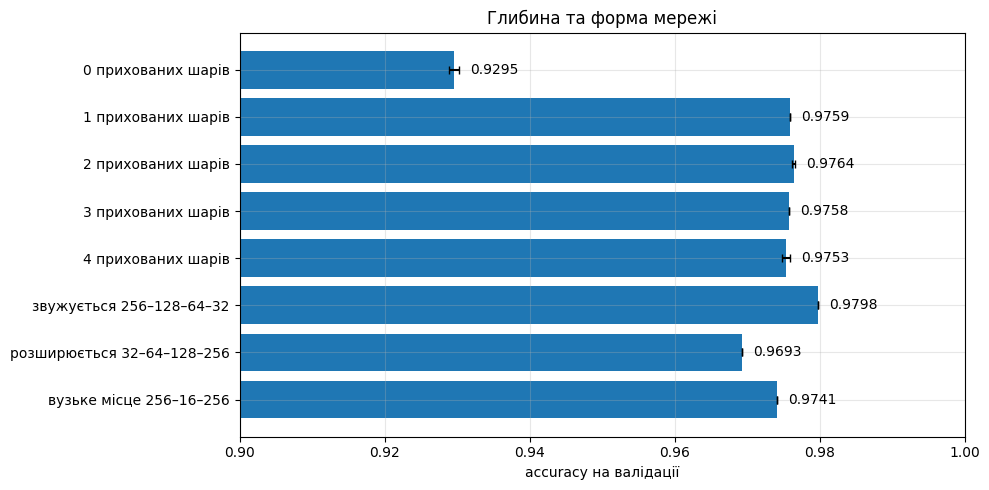

In [13]:
res = {"{} прихованих шарів".format(L): run([784] + [128] * L + [10]) for L in range(5)}
shapes = {"звужується 256–128–64–32": [256, 128, 64, 32], "розширюється 32–64–128–256": [32, 64, 128, 256], "вузьке місце 256–16–256": [256, 16, 256]}
res.update({k: run([784] + h + [10], seeds=(0,)) for k, h in shapes.items()})
t64 = table(res); display(t64.round(4))
FACTORS["Глибина та форма мережі"] = t64["accuracy (валід.)"]
bar_acc(t64, "Глибина та форма мережі", 0.9)

**Висновок.** Лінійна модель без прихованих шарів дає лише 0.9296 (навчальна 0.9255), тобто нелінійність важлива: один прихований шар додає 4.7 в.п. (0.9762). Додаткові шари нічого не додають: 0.9756 (2), 0.9762 (3), 0.9740 (4 шари), що не відрізняється від одного шару в межах розкиду (до ± 0.19 в.п.), але час навчання зростає з ≈ 5 до ≈ 9 с. Мережі різної форми (один запуск) дають 0.9715 (звужується та розширюється) та 0.9755 (вузьке місце 16 нейронів): відмінності до 0.5 в.п. не можна вважати суттєвими, адже розкид між запусками й похибка валідації порівнянні з ними.

### 6.5. Функція активації
Порівнюємо сигмоїду, гіперболічний тангенс, ReLU та leaky ReLU. Спочатку — у базовій мережі з одним прихованим шаром, потім — у глибшій (4 приховані шари по 128), де проявляється зникнення градієнта: там порівнюємо Adam та простий SGD зі швидкістю 0.1 (один запуск).

Один прихований шар:


,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
сигмоїда,0.9682,0.0005,0.9755,0.0074,101770,10.3324
tanh,0.9752,0.0000,0.9924,0.0172,101770,11.2207
ReLU,0.9759,0.0000,0.9932,0.0173,101770,10.2533
leaky ReLU,0.9762,0.0010,0.9928,0.0166,101770,12.6605


Чотири приховані шари (один запуск):


,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
"сигмоїда, Adam",0.9697,0.0,0.9860,0.0163,151306,21.2059
"сигмоїда, SGD",0.8871,0.0,0.8827,-0.0044,151306,13.7169
"tanh, Adam",0.9717,0.0,0.9904,0.0187,151306,16.3128
"tanh, SGD",0.9745,0.0,0.9907,0.0162,151306,12.1906
"ReLU, Adam",0.9748,0.0,0.9946,0.0198,151306,18.2936
"ReLU, SGD",0.9685,0.0,0.9894,0.0209,151306,12.4755


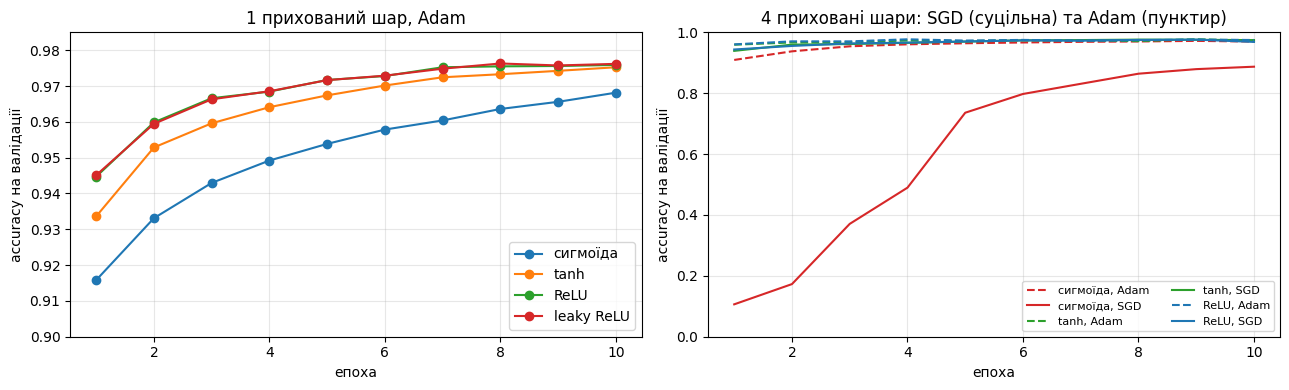

In [14]:
acts = {"сигмоїда": "sigmoid", "tanh": "tanh", "ReLU": "relu", "leaky ReLU": "leaky"}
res1 = {k: run([784, 128, 10], activation=a) for k, a in acts.items()}
deep = [784] + [128] * 4 + [10]
res2 = {"{}, {}".format(k, o): run(deep, seeds=(0,), activation=acts[k], optimizer=o.lower(), lr=lr)
        for k in ["сигмоїда", "tanh", "ReLU"] for o, lr in [("Adam", 1e-3), ("SGD", 0.1)]}
t65a, t65b = table(res1), table(res2)
print("Один прихований шар:"); display(t65a.round(4))
print("Чотири приховані шари (один запуск):"); display(t65b.round(4))
FACTORS["Функція активації"] = t65a["accuracy (валід.)"]

curve = lambda rs: np.mean([r["curve"] for r in rs], axis=0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, rs in res1.items():
    ax[0].plot(range(1, EP + 1), curve(rs), marker="o", label=k)
ax[0].set_title("1 прихований шар, Adam"); ax[0].set_ylim(0.9, 0.985)
colors = {"сигмоїда": "tab:red", "tanh": "tab:green", "ReLU": "tab:blue"}
for k, rs in res2.items():
    name, opt = k.split(", ")
    ax[1].plot(range(1, EP + 1), curve(rs), color=colors[name], ls="-" if opt == "SGD" else "--", label=k)
ax[1].set_title("4 приховані шари: SGD (суцільна) та Adam (пунктир)"); ax[1].set_ylim(0, 1)
for a in ax:
    a.set_xlabel("епоха"); a.set_ylabel("accuracy на валідації")
ax[0].legend(loc="lower right"); ax[1].legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Висновок.** У мережі з одним прихованим шаром ReLU (0.9762), leaky ReLU (0.9756) та tanh (0.9752) практично не відрізняються, а сигмоїда гірша (0.9682) і повільніше збігається (після першої епохи ≈ 0.92 проти ≈ 0.94 у ReLU). У глибшій мережі з 4 прихованими шарами та Adam результати схожі (ReLU 0.9759, tanh 0.9716, сигмоїда 0.9697), але з простим SGD (швидкість 0.1) сигмоїда практично не навчається за 10 епох (0.8871, accuracy росте від 0.11), тоді як tanh (0.9745) і ReLU (0.9705) навчаються. Імовірна причина — зникнення градієнта: похідна сигмоїди не перевищує 0.25, і сигнал слабшає від шару до шару; Adam це частково компенсує, нормуючи крок. Для глибших мереж зі швидкістю навчання, що не підлаштовується, варто брати ReLU або tanh. Глибокі мережі — один запуск.

### 6.6. Функція втрат
Порівнюємо крос-ентропію та середньоквадратичну помилку (на виході softmax) з оптимізаторами Adam і SGD (швидкість 0.1).

,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
"крос-ентропія, Adam",0.9759,0.0000,0.9932,0.0173,101770,11.8474
"крос-ентропія, SGD",0.9690,0.0005,0.9746,0.0056,101770,7.1078
"середньоквадратична, Adam",0.9762,0.0008,0.9916,0.0153,101770,10.9770
"середньоквадратична, SGD",0.9107,0.0001,0.8995,-0.0112,101770,7.1397


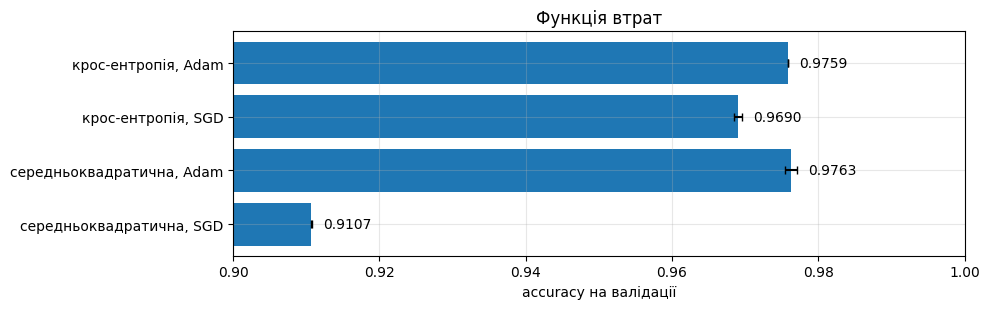

In [15]:
res = {"{}, {}".format(ln, o): run([784, 128, 10], loss=l, optimizer=o.lower(), lr=lr)
       for ln, l in [("крос-ентропія", "ce"), ("середньоквадратична", "mse")] for o, lr in [("Adam", 1e-3), ("SGD", 0.1)]}
t66 = table(res); display(t66.round(4))
FACTORS["Функція втрат"] = t66["accuracy (валід.)"]
bar_acc(t66, "Функція втрат", 0.9)

**Висновок.** З оптимізатором Adam крос-ентропія та середньоквадратична помилка дають однакову якість (0.9762 та 0.9762 ± 0.0007). Із простим SGD (швидкість 0.1) різниця велика: 0.9691 проти 0.9107, при цьому навчальна accuracy середньоквадратичної помилки лише 0.8995, тобто модель недонавчена. Імовірна причина — малий градієнт середньоквадратичної помилки на виході softmax, коли відповідь ще далека від істинної. Тому крос-ентропія (разом із softmax) — надійніший вибір для класифікації, особливо з простими оптимізаторами.

### 6.7. Оптимізатор і швидкість навчання
Для кожного оптимізатора (SGD, SGD з імпульсом 0.9, RMSprop, Adam) перебираємо швидкість навчання на логарифмічній сітці (один запуск на значення).

lr,0.0003,0.0010,0.0030,0.0100,0.0300,0.1000,0.3000,1.0000
оптимізатор,,,,,,,,
SGD,NaN,NaN,NaN,0.9264,0.9482,0.9685,0.9756,0.974
SGD з імпульсом,NaN,NaN,0.9484,0.9695,0.9742,0.9767,0.9682,NaN
RMSprop,0.9694,0.9755,0.9782,0.9764,0.9569,NaN,NaN,NaN
Adam,0.9689,0.9759,0.9766,0.9705,0.9461,NaN,NaN,NaN


,lr,accuracy (валід.),accuracy (навч.)
оптимізатор,,,
SGD,0.300,0.9756,0.9915
SGD з імпульсом,0.100,0.9767,0.9972
RMSprop,0.003,0.9782,0.9964
Adam,0.003,0.9766,0.9967


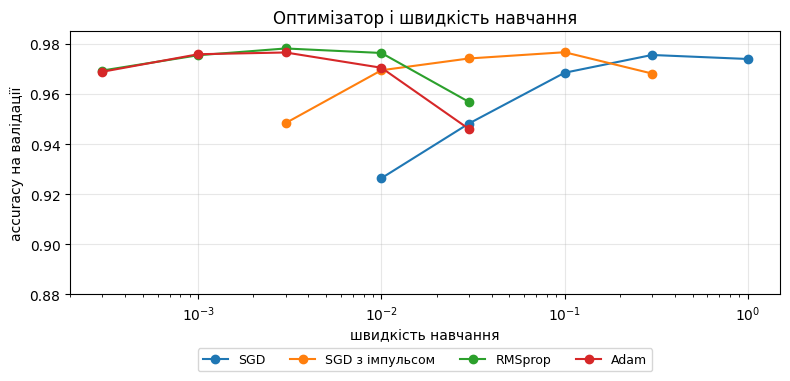

In [16]:
grid = {"SGD": ("sgd", [0.01, 0.03, 0.1, 0.3, 1.0]), "SGD з імпульсом": ("momentum", [0.003, 0.01, 0.03, 0.1, 0.3]),
        "RMSprop": ("rmsprop", [3e-4, 1e-3, 3e-3, 1e-2, 3e-2]), "Adam": ("adam", [3e-4, 1e-3, 3e-3, 1e-2, 3e-2])}
rows = []
for name, (o, lrs) in grid.items():
    for lr in lrs:
        r = run([784, 128, 10], seeds=(0,), optimizer=o, lr=lr)[0]
        rows.append({"оптимізатор": name, "lr": lr, "accuracy (валід.)": r["val"], "accuracy (навч.)": r["train"]})
t67 = pd.DataFrame(rows)
display(t67.pivot(index="оптимізатор", columns="lr", values="accuracy (валід.)").reindex(list(grid)).round(4))
best = t67.loc[t67.groupby("оптимізатор")["accuracy (валід.)"].idxmax()].set_index("оптимізатор").reindex(list(grid))
display(best.round(4))
FACTORS["Оптимізатор і швидкість навчання"] = t67["accuracy (валід.)"]

fig, ax = plt.subplots(figsize=(8, 4))
for name in grid:
    d = t67[t67["оптимізатор"] == name]
    ax.plot(d["lr"], d["accuracy (валід.)"], marker="o", label=name)
ax.set_xscale("log"); ax.set_xlabel("швидкість навчання"); ax.set_ylabel("accuracy на валідації"); ax.set_ylim(0.88, 0.985)
ax.set_title("Оптимізатор і швидкість навчання"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

**Висновок.** При правильно підібраній швидкості всі чотири оптимізатори дають однакову якість у межах шуму: SGD 0.9760 (швидкість 0.3), SGD з імпульсом 0.9755 (0.1), RMSprop 0.9771 (0.003), Adam 0.9762 (0.001). Оптимальна швидкість навчання відрізняється у сотні разів: для SGD 0.3, для Adam 0.001, і помилка у виборі швидкості коштує набагато більше, ніж вибір оптимізатора: для SGD 0.01 дає лише 0.9264, а для Adam 0.03 — 0.9555. Adam та RMSprop мають широкий діапазон добрих значень (0.0003–0.01 дає 0.969–0.977), тому з ними простіше починати; кожна точка — один запуск, тож різниці до ±0.2 в.п. не слід інтерпретувати.

### 6.8. Розмір батча
Змінюємо розмір міні-батча при фіксованих 10 епохах (один запуск); чим більший батч, тим менше кроків оптимізації за епоху.

,кроків за епоху,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с"
32,1563,0.9772,0.0,0.9974,0.0202,101770,34.2554
64,782,0.9770,0.0,0.9966,0.0196,101770,22.0384
128,391,0.9759,0.0,0.9937,0.0178,101770,8.9996
256,196,0.9740,0.0,0.9885,0.0145,101770,8.4869
512,98,0.9704,0.0,0.9804,0.0100,101770,4.8092
1024,49,0.9630,0.0,0.9685,0.0055,101770,6.4656


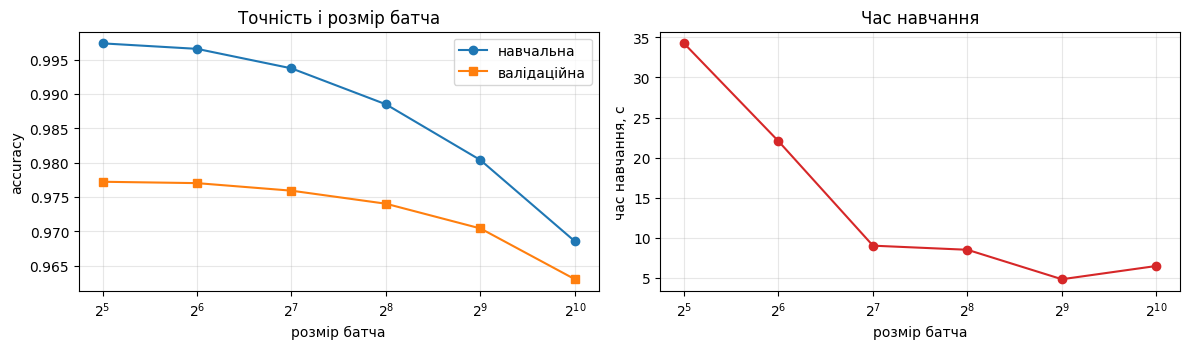

In [17]:
res = {bs: run([784, 128, 10], seeds=(0,), batch_size=bs) for bs in [32, 64, 128, 256, 512, 1024]}
t68 = table(res)
t68.insert(0, "кроків за епоху", [int(np.ceil(len(ytr) / bs)) for bs in res])
display(t68.round(4))
FACTORS["Розмір батча"] = t68["accuracy (валід.)"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(list(res), t68["accuracy (навч.)"], marker="o", label="навчальна"); ax[0].plot(list(res), t68["accuracy (валід.)"], marker="s", label="валідаційна")
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("розмір батча"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Точність і розмір батча"); ax[0].legend()
ax[1].plot(list(res), t68["час, с"], marker="o", color="tab:red"); ax[1].set_xscale("log", base=2); ax[1].set_xlabel("розмір батча"); ax[1].set_ylabel("час навчання, с"); ax[1].set_title("Час навчання")
plt.tight_layout(); plt.show()

**Висновок.** При фіксованих 10 епохах менший батч дає краще: 0.9792 (32), 0.9761 (64), 0.9762 (128), 0.9739 (256), 0.9703 (512), 0.9630 (1024), бо кількість кроків оптимізації за епоху зростає від 49 (батч 1 024) до 1 563 (батч 32), а навчальна accuracy при великому батчі нижча (0.9685 при 1 024: недонавчання). Ціна — час: ≈ 16 с на батч 32 проти ≈ 3 с на батч 1 024 (залежить від машини). Батч 128 — розумний компроміс. При більшій кількості епох великі батчі, імовірно, наздогнали б меншу якість, цього тут не перевіряли.

### 6.9. Регуляризація та перенавчання
Беремо більшу мережу 784–256–128–10 (235 тис. параметрів), навчаємо 12 епох і порівнюємо L2-штраф, dropout (частка відкинутих нейронів), їх комбінацію та ранню зупинку (до 40 епох; зупинка, якщо accuracy на валідації не покращується 3 епохи, повертаємо найкращі ваги). Показуємо втрати на валідації за епохами та розрив між навчальною і валідаційною accuracy.

,accuracy (валід.),± accuracy,accuracy (навч.),різниця навч.−валід.,параметрів,"час, с",епох
без регуляризації,0.9774,0.0,0.9956,0.0182,235146,27.9437,12
L2 = 1e-5,0.9755,0.0,0.9936,0.0181,235146,31.3443,12
L2 = 1e-4,0.9769,0.0,0.9942,0.0173,235146,35.3577,12
dropout 0.2,0.9815,0.0,0.9970,0.0155,235146,46.5193,12
dropout 0.5,0.9791,0.0,0.9893,0.0102,235146,48.2190,12
dropout 0.2 + L2 = 1e-4,0.9793,0.0,0.9951,0.0158,235146,50.0463,12
рання зупинка (patience = 3),0.9775,0.0,0.9951,0.0176,235146,23.6958,10


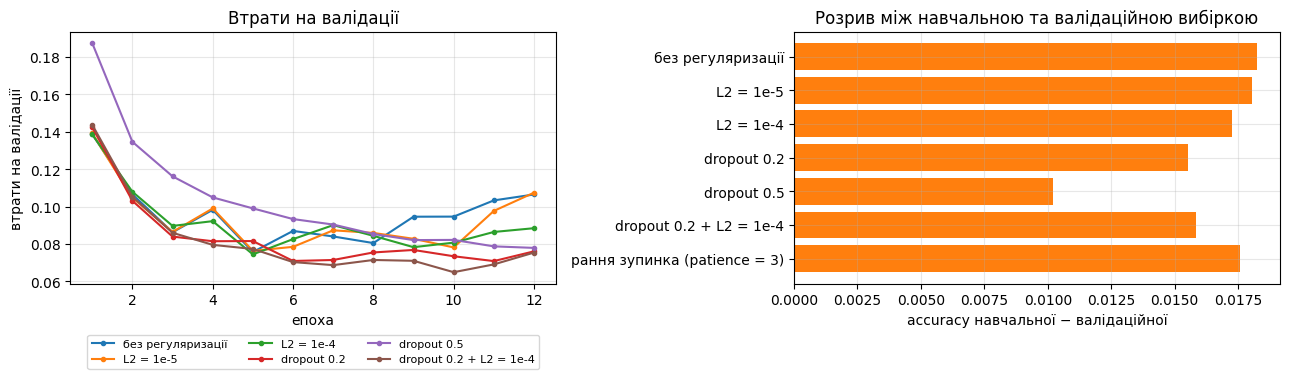

In [18]:
EP_REG = 12
reg = {"без регуляризації": {}, "L2 = 1e-5": {"l2": 1e-5}, "L2 = 1e-4": {"l2": 1e-4}, "dropout 0.2": {"dropout": 0.2},
       "dropout 0.5": {"dropout": 0.5}, "dropout 0.2 + L2 = 1e-4": {"dropout": 0.2, "l2": 1e-4}}
res = {k: run([784, 256, 128, 10], seeds=(0,), epochs=EP_REG, **kw) for k, kw in reg.items()}
res["рання зупинка (patience = 3)"] = run([784, 256, 128, 10], seeds=(0,), epochs=40, patience=3)
t69 = table(res); t69["епох"] = [r[0]["epochs"] for r in res.values()]
display(t69.round(4))
FACTORS["Регуляризація"] = t69["accuracy (валід.)"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, rs in res.items():
    if "рання" not in k:
        ax[0].plot(range(1, EP_REG + 1), rs[0]["curve_loss"], marker="o", ms=3, label=k)
ax[0].set_xlabel("епоха"); ax[0].set_ylabel("втрати на валідації"); ax[0].set_title("Втрати на валідації")
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
ax[1].barh(t69.index, t69["різниця навч.−валід."], color="tab:orange"); ax[1].invert_yaxis(); ax[1].set_xlabel("accuracy навчальної − валідаційної"); ax[1].set_title("Розрив між навчальною та валідаційною вибіркою")
plt.tight_layout(); plt.show()

**Висновок.** У мережі 784–256–128–10 без регуляризації втрати на валідації мінімальні на 5-й епосі (≈ 0.072) і потім ростуть до ≈ 0.103 на 12-й: це перенавчання за функцією втрат, хоча accuracy при цьому майже не падає. L2-штраф у перевіреному діапазоні (1e-5, 1e-4) майже не змінює результат (0.9773, 0.9763 проти 0.9771). Dropout 0.2 покращує accuracy до 0.9812 (+0.4 в.п.), а його комбінація з L2 = 1e-4 дає найкраще значення 0.9822 і одні з найнижчих втрат на валідації; dropout 0.5 найбільше зменшує розрив між навчальною та валідаційною accuracy (1.0 в.п. проти 2.0), але за 12 епох збігається повільніше (0.9785). Рання зупинка (найкраща епоха 9, 0.9797) дає схожий виграш без додаткових параметрів. Це по одному запуску, тому різниці 0.1–0.2 в.п. між варіантами регуляризації в межах шуму; вигода від dropout порівняно з відсутністю регуляризації (0.4–0.5 в.п.) помітніша.

### 6.10. Розмір навчальної вибірки
Навчаємо мережі різної ширини на перших n навчальних зображеннях (n від 500 до 50 000) із приблизно однаковою кількістю кроків оптимізації (≈ 2 500, але не менше 10 епох) та оцінюємо на повній валідаційній вибірці. Додатково — найширша мережа з dropout 0.5.

модель,784–32–10,784–128–10,784–512–10,"784–512–10, dropout 0.5"
n,,,,
500,0.8506,0.8577,0.8671,0.8698
1000,0.8830,0.8958,0.9027,0.9063
2000,0.9078,0.9182,0.9241,0.9317
5000,0.9244,0.9449,0.9515,0.9555
10000,0.9385,0.9556,0.9638,0.9690
20000,0.9518,0.9685,0.9727,0.9737
50000,0.9614,0.9759,0.9798,NaN


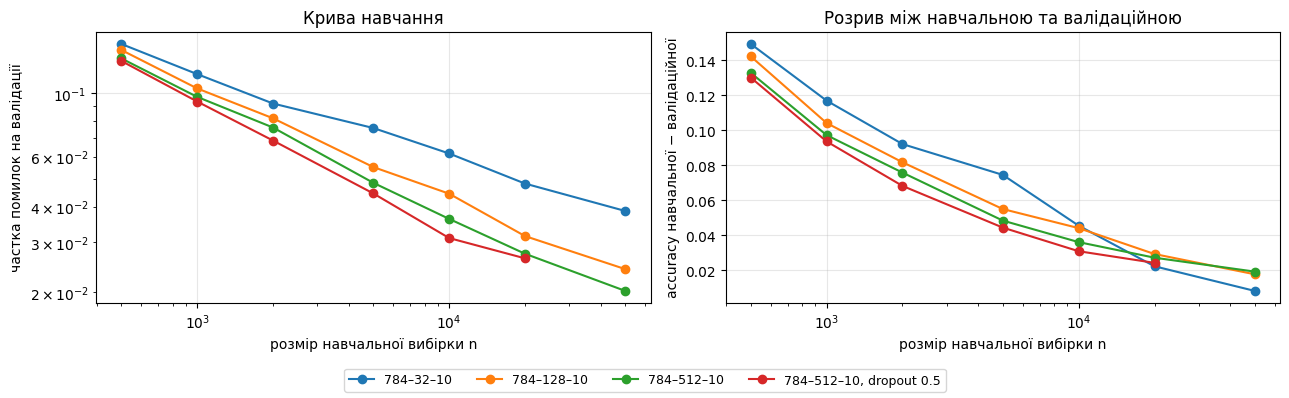

In [19]:
sizes_n = [500, 1000, 2000, 5000, 10000, 20000, 50000]
models = {"784–32–10": ([784, 32, 10], {}), "784–128–10": ([784, 128, 10], {}), "784–512–10": ([784, 512, 10], {}), "784–512–10, dropout 0.5": ([784, 512, 10], {"dropout": 0.5})}
rows = []
for name, (sz, kw) in models.items():
    for n in sizes_n:
        if "dropout" in name and n > 20000:
            continue
        ep = int(np.clip(round(2500 / np.ceil(n / 128)), 10, 300))             # ≈ 2 500 кроків оптимізації
        r = run(sz, seeds=(0,), epochs=ep, data=(Xtr[:n], ytr[:n], Xva, yva), eval_every=ep, **kw)[0]
        rows.append({"модель": name, "n": n, "accuracy (валід.)": r["val"], "accuracy (навч.)": r["train"]})
t610 = pd.DataFrame(rows)
display(t610.pivot(index="n", columns="модель", values="accuracy (валід.)")[list(models)].round(4))
FACTORS["Розмір навчальної вибірки (128 нейронів)"] = t610[t610["модель"] == "784–128–10"].set_index("n")["accuracy (валід.)"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in models:
    d = t610[t610["модель"] == name]
    ax[0].plot(d["n"], 1 - d["accuracy (валід.)"], marker="o", label=name)
    ax[1].plot(d["n"], d["accuracy (навч.)"] - d["accuracy (валід.)"], marker="o", label=name)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("розмір навчальної вибірки n"); ax[0].set_ylabel("частка помилок на валідації"); ax[0].set_title("Крива навчання")
ax[1].set_xscale("log"); ax[1].set_xlabel("розмір навчальної вибірки n"); ax[1].set_ylabel("accuracy навчальної − валідаційної"); ax[1].set_title("Розрив між навчальною та валідаційною")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

**Висновок.** Помилка зменшується приблизно за степеневим законом із ростом навчальної вибірки: для мережі з 128 нейронами від 14.2% при n = 500 до 2.4% при n = 50 000 (у ≈ 6 разів при стократному зростанні даних). При малих n мережа запам'ятовує навчальні дані: розрив між навчальною та валідаційною accuracy ≈ 13–15 в.п. при n = 500 і ≈ 1–2 в.п. при n = 50 000. Мала мережа (32 нейрони) насичується раніше й завжди гірша; на 50 000 вона відстає на 1.5 в.п. (0.9617 проти 0.9762). Dropout 0.5 допомагає найбільше на малих вибірках: при n = 2 000 — 0.9315 проти 0.9240 (+0.75 в.п.), при n = 10 000 — 0.9695 проти 0.9638, а при n = 20 000 різниця лише 0.1 в.п. Тобто регуляризація потрібніша, коли даних мало, а додаткові дані дають більше, ніж будь-яка зміна архітектури.

### 6.11. Перехресна перевірка
Оцінюємо три кандидати за стратифікованою 5-кратною перехресною перевіркою на об'єднаних навчальній і валідаційній вибірках (60 000): лінійну модель (784–10), базову 784–128–10 та 784–256–128–10 із dropout 0.2 (12 епох). Усі кандидати навчаються на тих самих розбиттях, тому різницю можна порівнювати попарно за фолдами.

,784–10 (лінійна),784–128–10 (базова),"784–256–128–10, dropout 0.2"
фолд 1,0.9190,0.9743,0.9784
фолд 2,0.9238,0.9758,0.9804
фолд 3,0.9218,0.9743,0.9801
фолд 4,0.9205,0.9724,0.9807
фолд 5,0.9208,0.9739,0.9772


,середнє,σ за фолдами,мін,макс
784–10 (лінійна),0.9212,0.0018,0.9190,0.9238
784–128–10 (базова),0.9742,0.0012,0.9724,0.9758
"784–256–128–10, dropout 0.2",0.9794,0.0015,0.9772,0.9807


Різниця «784–256–128–10, dropout 0.2» − «784–128–10 (базова)» за фолдами: середнє +0.0052, σ 0.0019, краща в 5 з 5 фолдів


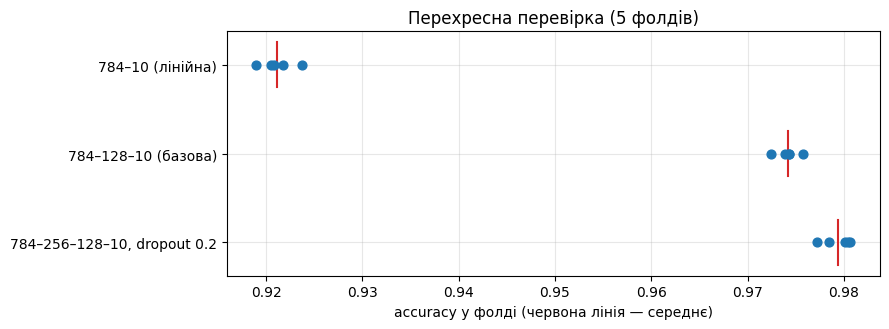

In [20]:
EP_CV = 12
cands = {"784–10 (лінійна)": ([784, 10], {}, EP), "784–128–10 (базова)": ([784, 128, 10], {}, EP), "784–256–128–10, dropout 0.2": ([784, 256, 128, 10], {"dropout": 0.2}, EP_CV)}
skf = StratifiedKFold(5, shuffle=True, random_state=42)
folds = list(skf.split(Xall, yall))
cv = {}
for name, (sz, kw, ep) in cands.items():
    cv[name] = [accuracy_score(yall[va], MLP(sz, seed=0, **kw).fit(Xall[tr], yall[tr], epochs=ep, eval_every=10 ** 6).predict(Xall[va])) for tr, va in folds]
cv_df = pd.DataFrame(cv, index=["фолд {}".format(i + 1) for i in range(5)])
summary_cv = pd.DataFrame({"середнє": cv_df.mean(), "σ за фолдами": cv_df.std(ddof=1), "мін": cv_df.min(), "макс": cv_df.max()})
display(cv_df.round(4)); display(summary_cv.round(4))
names = list(cands)
d = cv_df[names[2]] - cv_df[names[1]]
print("Різниця «{}» − «{}» за фолдами: середнє {:+.4f}, σ {:.4f}, краща в {} з 5 фолдів".format(names[2], names[1], d.mean(), d.std(ddof=1), int((d > 0).sum())))

fig, ax = plt.subplots(figsize=(9, 3.4))
for i, name in enumerate(names):
    ax.scatter(cv_df[name], [i] * 5, s=40, color="tab:blue", zorder=3)
    ax.plot([cv_df[name].mean()] * 2, [i - 0.25, i + 0.25], color="tab:red")
ax.set_yticks(range(3)); ax.set_yticklabels(names); ax.invert_yaxis(); ax.set_xlabel("accuracy у фолді (червона лінія — середнє)"); ax.set_title("Перехресна перевірка (5 фолдів)")
plt.tight_layout(); plt.show()

**Висновок.** За 5-кратною стратифікованою перехресною перевіркою: лінійна модель 0.9212 ± 0.0018, базова 784–128–10 — 0.9743 ± 0.0011, 784–256–128–10 із dropout 0.2 — 0.9795 ± 0.0013. Розкид між фолдами (≈ 0.1–0.2 в.п.) порівнянний із розкидом між початковими вагами (п. 6) і з похибкою оцінки на 10 000 зображеннях. Різниця останніх двох моделей +0.52 в.п. (σ за фолдами 0.13 в.п.), і друга краща в усіх 5 фолдах, тому перевага підтверджується; лінійна модель відстає на ≈ 5 в.п. Оцінка базової моделі за перехресною перевіркою (0.9743) близька до її оцінки на валідації (0.9762) та на тесті (0.9782).

### 6.12. Зведення: які фактори впливають найсильніше
Для кожного фактора — мінімальне та максимальне значення accuracy на валідації серед перевірених значень і розмах (max − min). Нульову ініціалізацію ваг (accuracy 0.106) у зведення не включено як вироджений випадок.

,min,max,розмах
Ініціалізація ваг (без нульових),0.9734,0.9763,0.0029
Регуляризація,0.9755,0.9815,0.0060
Функція активації,0.9682,0.9762,0.0080
Розмір батча,0.9630,0.9772,0.0142
Масштабування входу,0.9494,0.9760,0.0266
Глибина та форма мережі,0.9296,0.9798,0.0503
Оптимізатор і швидкість навчання,0.9264,0.9782,0.0518
Функція втрат,0.9107,0.9762,0.0656
Розмір навчальної вибірки (128 нейронів),0.8577,0.9759,0.1182
Ширина прихованого шару,0.8537,0.9798,0.1261


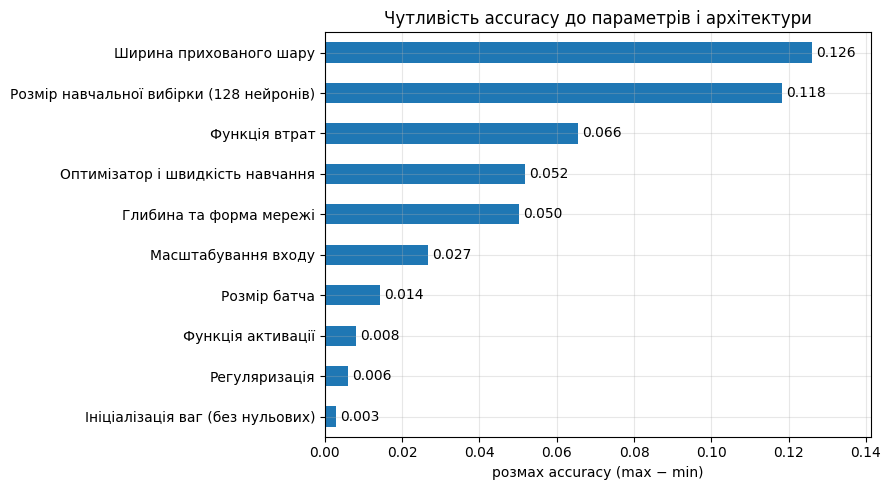

In [21]:
summary_df = pd.DataFrame({k: {"min": v.min(), "max": v.max(), "розмах": v.max() - v.min()} for k, v in FACTORS.items()}).T.sort_values("розмах")
display(summary_df.round(4))
ax = summary_df["розмах"].plot.barh(figsize=(9, 5), color="tab:blue")
ax.set_xlabel("розмах accuracy (max − min)"); ax.set_title("Чутливість accuracy до параметрів і архітектури")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); ax.margins(x=0.12); plt.tight_layout(); plt.show()

**Висновок.** Найбільший розмах accuracy дають ширина прихованого шару (0.126) і розмір навчальної вибірки (0.119), далі функція втрат (0.065, через поєднання середньоквадратичної помилки з простим SGD), оптимізатор і швидкість навчання (0.051), глибина та форма (0.047, через лінійну модель) і масштабування входу (0.028). Розмах для розміру батча 0.016, функції активації 0.008, регуляризації 0.006 та ініціалізації без нульових ваг 0.003. Нульова ініціалізація (0.106) ламає навчання зовсім, тому її в зведення не включено. Розмах залежить від того, які крайні значення ми перевіряли (4 нейрони, MSE із SGD тощо): він показує чутливість, а не те, наскільки важливо налаштовувати фактор у розумних межах. Практично: спочатку потрібна достатня ємність, дані та адекватні масштаб входу й швидкість навчання, а вибір активації, регуляризації та батча дає зсув у частки відсотка.

## 7. Підбір моделі та оцінка на тестових даних
За результатами п. 6 вибираємо підсумкову модель: 784–256–128–10, ReLU, Adam (0.001), батч 128, dropout 0.2 і рання зупинка за валідацією (до 40 епох, patience = 3). Навчаємо три мережі з різними початковими вагами, оцінюємо на тесті (вперше після базової моделі), перевіряємо ансамбль із трьох мереж (усереднення ймовірностей) і порівнюємо з базовою моделлю: довірчий інтервал методом бутстрепу та точний біноміальний тест на розбіжностях у відповідях.

Епох до зупинки (з урахуванням patience): [10, 19, 11] | параметрів: 235146


,accuracy,precision,recall,F1
мережа seed 0,0.9802,0.9801,0.9801,0.9800
мережа seed 1,0.9822,0.9821,0.9820,0.9821
мережа seed 2,0.9809,0.9808,0.9807,0.9808


,accuracy,precision,recall,F1,помилок із 10 000
базова (п. 5),0.9778,0.9778,0.9775,0.9777,222.0000
"підсумкова, середнє за 3 seed",0.9811,0.9810,0.9810,0.9810,189.0000
"підсумкова, σ за 3 seed",0.0008,0.0009,0.0008,0.0008,8.2865
ансамбль із 3 мереж,0.9835,0.9835,0.9834,0.9834,165.0000


95% інтервал accuracy: базова 0.9749–0.9805; підсумкова 0.9773–0.9829
Різниця accuracy (підсумкова − базова) = +0.0024, 95% інтервал [-0.0001; +0.0048]
Лише підсумкова права: 87, лише базова права: 63, p-значення біноміального тесту = 0.0600


цифра,0,1,2,3,4,5,6,7,8,9
F1 базова,0.9843,0.9890,0.9764,0.9753,0.9755,0.9773,0.9791,0.9781,0.9707,0.9709
F1 підсумкова,0.9873,0.9929,0.9769,0.9816,0.9769,0.9804,0.9813,0.9771,0.9731,0.9729
recall базова,0.9929,0.9868,0.9826,0.9762,0.9715,0.9652,0.9781,0.9776,0.9702,0.9742
recall підсумкова,0.9918,0.9903,0.9835,0.9792,0.9684,0.9832,0.9854,0.9737,0.9671,0.9782
помилок базова,7.0000,15.0000,18.0000,24.0000,28.0000,31.0000,21.0000,23.0000,29.0000,26.0000
помилок підсумкова,8.0000,11.0000,17.0000,21.0000,31.0000,15.0000,14.0000,27.0000,32.0000,22.0000


Найчастіші помилки підсумкової моделі (істинна → прогноз: кількість): 4 → 9: 16; 7 → 2: 11; 8 → 2: 8; 7 → 9: 7; 8 → 9: 6; 3 → 7: 6


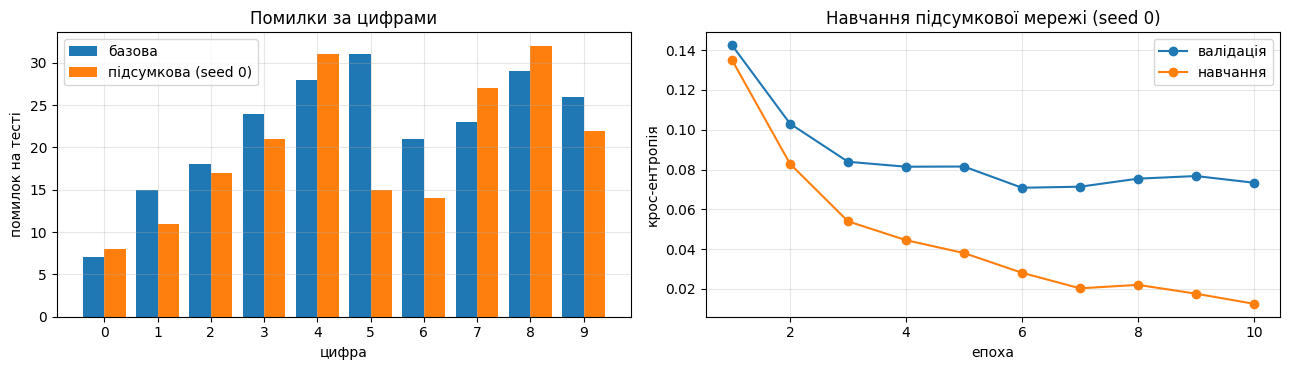

In [22]:
from scipy.stats import binomtest

FINAL = dict(sizes=[784, 256, 128, 10], activation="relu", optimizer="adam", lr=1e-3, dropout=0.2, batch_size=128)
nets, t_final = [], []
for s in (0, 1, 2):
    t0 = time.perf_counter()
    nets.append(MLP(FINAL["sizes"], seed=s, **{k: v for k, v in FINAL.items() if k != "sizes"}).fit(Xtr, ytr, Xva, yva, epochs=40, patience=3))
    t_final.append(time.perf_counter() - t0)
print("Епох до зупинки (з урахуванням patience):", [len(n.history) for n in nets], "| параметрів:", nets[0].n_params())

ms = pd.DataFrame([metrics(yte, n.predict(Xte)) for n in nets], index=["мережа seed {}".format(s) for s in range(3)])
P_ens = np.mean([n.predict_proba(Xte) for n in nets], axis=0)
final_tab = pd.DataFrame({"базова (п. 5)": m_base, "підсумкова, середнє за 3 seed": ms.mean(), "підсумкова, σ за 3 seed": ms.std(ddof=0),
                          "ансамбль із 3 мереж": metrics(yte, P_ens.argmax(axis=1))}).T
final_tab["помилок із 10 000"] = [(pred_base != yte).sum(), np.mean([(n.predict(Xte) != yte).sum() for n in nets]), np.std([(n.predict(Xte) != yte).sum() for n in nets]), (P_ens.argmax(axis=1) != yte).sum()]
display(ms.round(4)); display(final_tab.round(4))

# порівняння підсумкової мережі (seed 0) з базовою
pred_f = nets[0].predict(Xte)
ok_b, ok_f = pred_base == yte, pred_f == yte
rng = np.random.default_rng(0)
idx = rng.integers(0, len(yte), (1000, len(yte)))
ci = lambda a: np.percentile(a, [2.5, 97.5])
d = ok_f[idx].mean(axis=1) - ok_b[idx].mean(axis=1)
only_f, only_b = int((ok_f & ~ok_b).sum()), int((ok_b & ~ok_f).sum())
print("95% інтервал accuracy: базова {:.4f}–{:.4f}; підсумкова {:.4f}–{:.4f}".format(*ci(ok_b[idx].mean(axis=1)), *ci(ok_f[idx].mean(axis=1))))
print("Різниця accuracy (підсумкова − базова) = {:+.4f}, 95% інтервал [{:+.4f}; {:+.4f}]".format(ok_f.mean() - ok_b.mean(), *ci(d)))
print("Лише підсумкова права: {}, лише базова права: {}, p-значення біноміального тесту = {:.4f}".format(only_f, only_b, binomtest(only_f, only_f + only_b, 0.5).pvalue))

p, r, f, s = precision_recall_fscore_support(yte, pred_f, zero_division=0)
cls = pd.DataFrame({"F1 базова": per_class["F1"], "F1 підсумкова": f, "recall базова": per_class["recall"], "recall підсумкова": r,
                    "помилок базова": [(pred_base[yte == c] != c).sum() for c in CLASSES], "помилок підсумкова": [(pred_f[yte == c] != c).sum() for c in CLASSES]}, index=pd.Index(CLASSES, name="цифра"))
display(cls.round(4).T)
cmf = confusion_matrix(yte, pred_f); offf = cmf - np.diag(np.diag(cmf))
top = np.dstack(np.unravel_index(np.argsort(-offf.ravel())[:6], offf.shape))[0]
print("Найчастіші помилки підсумкової моделі (істинна → прогноз: кількість):", "; ".join("{} → {}: {}".format(i, j, offf[i, j]) for i, j in top))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
w = 0.4
ax[0].bar(np.arange(10) - w / 2, cls["помилок базова"], w, label="базова"); ax[0].bar(np.arange(10) + w / 2, cls["помилок підсумкова"], w, label="підсумкова (seed 0)")
ax[0].set_xticks(CLASSES); ax[0].set_xlabel("цифра"); ax[0].set_ylabel("помилок на тесті"); ax[0].set_title("Помилки за цифрами"); ax[0].legend()
ax[1].plot(range(1, len(nets[0].history) + 1), [h["val_loss"] for h in nets[0].history], marker="o", label="валідація"); ax[1].plot(range(1, len(nets[0].history) + 1), [h["train_loss"] for h in nets[0].history], marker="o", label="навчання")
ax[1].set_xlabel("епоха"); ax[1].set_ylabel("крос-ентропія"); ax[1].set_title("Навчання підсумкової мережі (seed 0)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Висновок.** Підсумкова мережа 784–256–128–10 (dropout 0.2, рання зупинка, 10–18 епох) дає на тесті accuracy 0.9800, 0.9782 та 0.9803 для трьох початкових станів, у середньому 0.9795 ± 0.0009 (F1 0.9794; 205 помилок із 10 000). Базова модель — 0.9782 (218 помилок). Різниця для seed 0 становить +0.18 в.п., 95% інтервал [−0.06; +0.42] в.п., і біноміальний тест на розбіжностях (84 проти 66, p = 0.165) не підтверджує, що підсумкова краща за базову; а перевага +0.5 в.п. з перехресної перевірки (п. 6.11) на тесті проявилась слабше: +0.1–0.2 в.п. у середньому за три мережі, в межах похибки. Ансамбль із трьох мереж (усереднення ймовірностей) дає 0.9833 (167 помилок), на 51 помилку менше за базову модель. За цифрами помітне покращення для 5 (помилок 29 → 14) та 1 (15 → 11), для 4 та 7 незначне погіршення (26 → 28, 25 → 29), що в межах шуму. Найчастіші помилки ті самі: 4 → 9 (15), 7 → 2 (12), 7 → 9 (9), 8 → 2 (8), 9 → 4 (7), 3 → 5 (7), тобто це системні плутанини схожих за формою цифр.

## 8. Стійкість до шуму та змагальних прикладів (FGSM)
Нейронні мережі, які використовують у системах безпеки, можуть бути об'єктом атак, що змінюють вхід так, щоб ввести модель в оману. Перевіряємо два типи збурень тестових зображень: випадковий гауссів шум із різним σ та змагальні приклади методу FGSM, де кожен піксель зсувається на ε у напрямку, що збільшує втрати (градієнт за входом дає зворотне поширення). Значення пікселів обмежуємо діапазоном 0..1. Порівнюємо лінійну модель, базову та підсумкову мережі.

,лінійна 784–10,базова 784–128–10,підсумкова
ε (FGSM),,,
0.00,0.9233,0.9778,0.9802
0.05,0.3894,0.4630,0.7183
0.10,0.0353,0.0556,0.2615
0.15,0.0008,0.0165,0.0852
0.20,0.0000,0.0039,0.0363
0.30,0.0000,0.0005,0.0082


,лінійна 784–10,базова 784–128–10,підсумкова
σ (шум),,,
0.0,0.9233,0.9778,0.9802
0.1,0.8965,0.9591,0.9692
0.2,0.7058,0.8146,0.8776
0.3,0.4814,0.6470,0.7060
0.5,0.3025,0.3937,0.4622


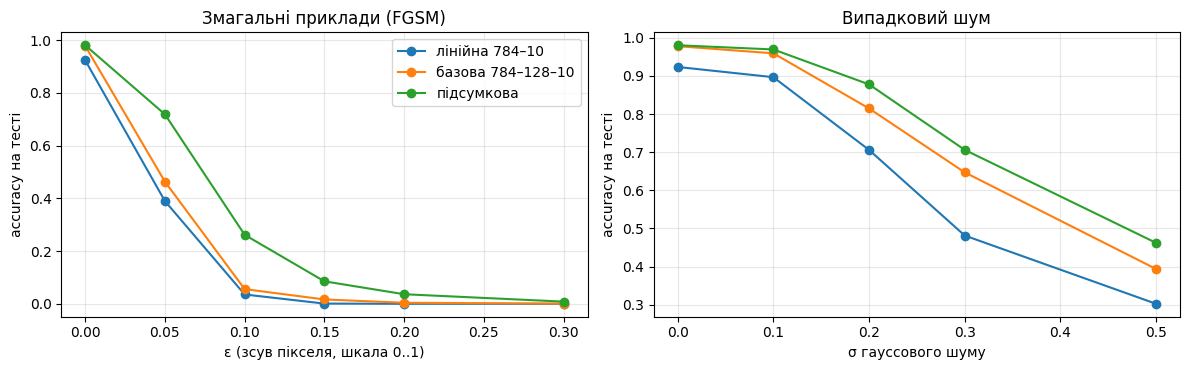

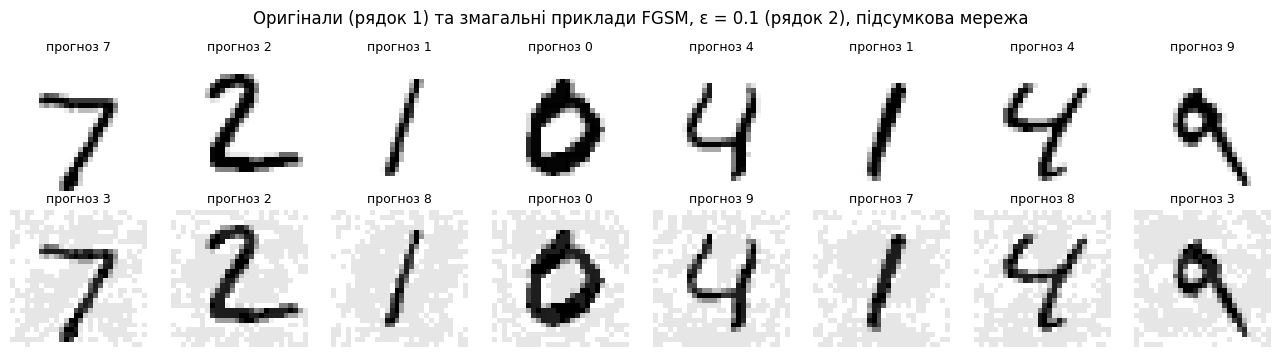

In [23]:
lin = MLP([784, 10], seed=0).fit(Xtr, ytr, epochs=EP, eval_every=EP)
models8 = {"лінійна 784–10": lin, "базова 784–128–10": base, "підсумкова": nets[0]}
eps_list, sig_list = [0, 0.05, 0.1, 0.15, 0.2, 0.3], [0, 0.1, 0.2, 0.3, 0.5]

def fgsm(net, X, y, eps):
    """Змагальні приклади: зсув кожного пікселя на ε у напрямку градієнта втрат за входом."""
    return np.clip(X + eps * np.sign(net.input_grad(X, y)), 0, 1)

acc_fgsm = pd.DataFrame({k: [accuracy_score(yte, net.predict(fgsm(net, Xte, yte, e))) for e in eps_list] for k, net in models8.items()}, index=pd.Index(eps_list, name="ε (FGSM)"))
rng = np.random.default_rng(0)
noisy = {s: np.clip(Xte + rng.normal(0, s, Xte.shape).astype(np.float32), 0, 1) for s in sig_list}
acc_noise = pd.DataFrame({k: [accuracy_score(yte, net.predict(noisy[s])) for s in sig_list] for k, net in models8.items()}, index=pd.Index(sig_list, name="σ (шум)"))
display(acc_fgsm.round(4)); display(acc_noise.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k in models8:
    ax[0].plot(eps_list, acc_fgsm[k], marker="o", label=k); ax[1].plot(sig_list, acc_noise[k], marker="o", label=k)
ax[0].set_xlabel("ε (зсув пікселя, шкала 0..1)"); ax[0].set_ylabel("accuracy на тесті"); ax[0].set_title("Змагальні приклади (FGSM)")
ax[1].set_xlabel("σ гауссового шуму"); ax[1].set_ylabel("accuracy на тесті"); ax[1].set_title("Випадковий шум")
ax[0].legend(); plt.tight_layout(); plt.show()

net = nets[0]; good = np.flatnonzero(net.predict(Xte) == yte)[:8]
Xadv = fgsm(net, Xte[good], yte[good], 0.1)
fig, ax = plt.subplots(2, 8, figsize=(13, 3.6))
for k in range(8):
    ax[0, k].imshow(Xte[good[k]].reshape(28, 28), cmap="gray_r"); ax[0, k].set_title("прогноз {}".format(net.predict(Xte[good[k]:good[k] + 1])[0]), fontsize=9)
    ax[1, k].imshow(Xadv[k].reshape(28, 28), cmap="gray_r"); ax[1, k].set_title("прогноз {}".format(net.predict(Xadv[k:k + 1])[0]), fontsize=9)
for a in ax.ravel():
    a.axis("off")
fig.suptitle("Оригінали (рядок 1) та змагальні приклади FGSM, ε = 0.1 (рядок 2), підсумкова мережа")
plt.tight_layout(); plt.show()

**Висновок.** Малі цілеспрямовані збурення руйнують розпізнавання: для підсумкової мережі accuracy падає з 0.9800 до 0.7107 при ε = 0.05, до 0.2416 при ε = 0.1 (кожен піксель змінено не більше ніж на 10% діапазону) і до 0.0068 при ε = 0.3; для базової 0.4659 та 0.0568, для лінійної — 0.3894 та 0.0353 (ε = 0.05 та 0.1). Випадковий шум того самого порядку майже не шкодить: при σ = 0.1 accuracy підсумкової мережі 0.9678 (проти 0.2416 для FGSM із ε = 0.1), і лише при σ = 0.3 вона падає до 0.7019. Підсумкова мережа стійкіша за базову та лінійну в обох випадках (імовірно, завдяки більшій ємності та dropout), але теж «ламається». Для систем кібербезпеки, що використовують нейромережі, це означає, що висока accuracy на звичайних даних не гарантує стійкості до навмисно змінених входів (ухилення від детекторів). Атаку обчислено за градієнтами тієї самої моделі (white-box); захисти (наприклад, навчання на змагальних прикладах) тут не перевірялись.

## 9. Порівняння з іншими алгоритмами
Порівнюємо підсумкову нейронну мережу на тестових даних із бібліотечною `MLPClassifier` (така сама архітектура, без dropout), логістичною регресією, методом k найближчих сусідів (k = 3) та методом опорних векторів із RBF-ядром на 50 головних компонентах (PCA), які навчаємо на тій самій навчальній вибірці (50 000). Час залежить від машини.

,accuracy,F1,"навчання, с","прогноз 10 000 зображень, с"
наша нейронна мережа (підсумкова),0.9802,0.9800,40.3075,0.0619
sklearn MLPClassifier (256–128),0.9800,0.9799,30.5495,0.0615
логістична регресія,0.9254,0.9243,28.5927,0.0641
kNN (k = 3),0.9681,0.9679,0.0289,23.0089
SVM (RBF) на 50 головних компонентах,0.9851,0.9850,17.1769,9.4988


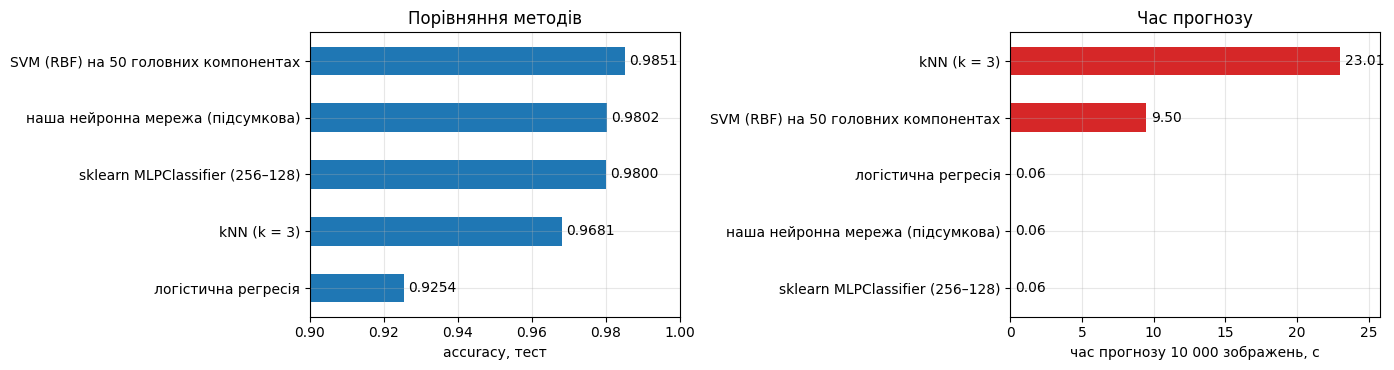

In [24]:
rows = {}
def add(name, fit, predict):
    t0 = time.perf_counter(); model = fit(); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = predict(model); t_pred = time.perf_counter() - t0
    m = metrics(yte, pred)
    rows[name] = {"accuracy": m["accuracy"], "F1": m["F1"], "навчання, с": t_fit, "прогноз 10 000 зображень, с": t_pred}

add("наша нейронна мережа (підсумкова)", lambda: nets[0], lambda m: m.predict(Xte)); rows["наша нейронна мережа (підсумкова)"]["навчання, с"] = t_final[0]
add("sklearn MLPClassifier (256–128)", lambda: MLPClassifier((256, 128), alpha=0, batch_size=128, max_iter=12, random_state=0).fit(Xtr, ytr), lambda m: m.predict(Xte))
add("логістична регресія", lambda: LogisticRegression(max_iter=100).fit(Xtr, ytr), lambda m: m.predict(Xte))
add("kNN (k = 3)", lambda: KNeighborsClassifier(3, n_jobs=-1).fit(Xtr, ytr), lambda m: m.predict(Xte))
pca = PCA(50, random_state=0).fit(Xtr)
add("SVM (RBF) на 50 головних компонентах", lambda: SVC(C=5).fit(pca.transform(Xtr), ytr), lambda m: m.predict(pca.transform(Xte)))
cmp_all = pd.DataFrame(rows).T
display(cmp_all.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
cmp_all["accuracy"].sort_values().plot.barh(ax=ax[0], color="tab:blue"); ax[0].set_xlim(0.9, 1); ax[0].set_xlabel("accuracy, тест"); ax[0].set_title("Порівняння методів")
ax[0].bar_label(ax[0].containers[0], fmt="%.4f", padding=3)
cmp_all["прогноз 10 000 зображень, с"].sort_values().plot.barh(ax=ax[1], color="tab:red"); ax[1].set_xlabel("час прогнозу 10 000 зображень, с"); ax[1].set_title("Час прогнозу")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f", padding=3); ax[1].margins(x=0.12)
plt.tight_layout(); plt.show()

**Висновок.** Підсумкова нейронна мережа (0.9800) збігається за якістю з бібліотечною `MLPClassifier` тієї ж архітектури (0.9800), краща за kNN (0.9681) та логістичну регресію (0.9244), але поступається SVM з RBF-ядром на 50 головних компонентах (0.9851): різниця 0.5 в.п. (≈ 51 зображення з 10 000) більша за випадкову похибку тесту (≈ ±0.3 в.п.). Ансамбль із трьох мереж (0.9833) скорочує цей розрив. Нейронна мережа найшвидше прогнозує серед нелінійних методів (≈ 0.05 с на 10 000 зображень проти ≈ 5.4 с у SVM та ≈ 7.5 с у kNN, залежить від машини), але навчається довше за SVM на PCA (≈ 21 с проти ≈ 12 с) і потребує підбору гіперпараметрів. Тому для вузької задачі на готових векторних ознаках SVM — сильний конкурент; перевага нейронних мереж проявляється при більших даних і при зображеннях без попереднього зменшення розмірності, цього тут не перевіряли.

## 10. Переваги та недоліки нейронних мереж
**Переваги**
- Висока якість на зображеннях без ручного добору ознак: 0.980 (одна мережа) і 0.983 (ансамбль із трьох) на тесті MNIST проти 0.924 у лінійної моделі.
- Швидкий прогноз: ≈ 0.05 с на 10 000 зображень, у ≈ 100–160 разів швидше за SVM та kNN (залежить від машини), і не потрібно зберігати навчальну вибірку.
- Гнучкість: архітектуру, активації, функцію втрат, оптимізатор і регуляризацію можна міняти, а якість зростає зі збільшенням даних (помилка 14.2% → 2.4% при зростанні n з 500 до 50 000).
- Простий алгоритм навчання: зворотне поширення помилки з будь-яким оптимізатором, градієнти перевіряються числовим методом.

**Недоліки**
- Багато гіперпараметрів і чутливість до них: швидкість навчання, масштаб входу (0.949 для 0..255 проти 0.976 для 0..1), ініціалізація (нульові ваги дають 0.106).
- Схильність до перенавчання: розрив між навчальною та валідаційною accuracy ≈ 2 в.п. на 50 000 зображеннях і ≈ 14 в.п. на 500; потрібні dropout, рання зупинка або більше даних.
- Нестійкість до змагальних прикладів: FGSM з ε = 0.1 знижує accuracy з 0.980 до 0.242.
- Результат залежить від випадкових початкових ваг (σ ≈ 0.1 в.п. на тесті), тож для надійної оцінки потрібні кілька запусків або перехресна перевірка.
- Низька інтерпретованість, і не обов'язково найкраща якість: SVM на PCA дав 0.985 і навчився швидше (≈ 12 с проти ≈ 21 с).

## 11. Загальні висновки
1. Реалізовано багатошарову нейронну мережу з зворотним поширенням помилки на NumPy; градієнти збігаються з числовими (відносна різниця до 2.5·10⁻⁷), а на MNIST якість така сама, як у `MLPClassifier` (0.9762 і 0.9760 на валідації, 0.9800 і 0.9800 для підсумкової архітектури на тесті).
2. Базова мережа 784–128–10 дає 0.9782 на тесті (precision 0.9783, recall 0.9780, F1 0.9781); підсумкова 784–256–128–10 з dropout 0.2 та ранньою зупинкою — 0.9795 ± 0.0009, а ансамбль із трьох мереж — 0.9833. Різниця між базовою і підсумковою моделями на тесті статистично не підтверджена (p = 0.165), хоча перехресна перевірка дала +0.52 в.п. (краща в 5 з 5 фолдів).
3. Найсильніше на результат впливають ємність і кількість даних (ширина: від 0.854 до 0.980, розмір вибірки: помилка 14.2% → 2.4%), а також масштаб входу та швидкість навчання; один прихований шар уже достатній (лінійна модель 0.930, 2–4 шари не покращують), активація, регуляризація та батч дають зміни в частки відсотка.
4. ReLU та tanh працюють однаково добре, сигмоїда гірша й у глибокій мережі з SGD майже не навчається (0.887); крос-ентропія надійніша за середньоквадратичну помилку з простими оптимізаторами (0.969 проти 0.911); при правильній швидкості навчання всі оптимізатори дають 0.975–0.977.
5. Dropout (до 0.9822 у комбінації з L2) та рання зупинка зменшують перенавчання, особливо на малих вибірках (+0.75 в.п. при n = 2 000); правило з методички n ≈ w/e для MNIST надто песимістичне.
6. Мережа вразлива до змагальних прикладів: FGSM з ε = 0.1 знижує accuracy підсумкової моделі до 0.242, тоді як випадковий шум з σ = 0.1 — лише до 0.968. Для задач кібербезпеки це означає, що перевіряти слід не лише точність, а й стійкість до навмисних збурень.
7. SVM із PCA (0.9851) виявився кращим за нейронну мережу на цих даних, а мережа швидше прогнозує. Обмеження: оцінки гіперпараметрів — переважно 1–2 запуски (розкид до ± 0.2 в.п.), тест має 10 000 зображень (похибка ≈ ± 0.3 в.п.), час залежить від машини, а стійкість перевірено лише для атаки FGSM на ті самі моделі.